# Phát hiện drift dựa trên nhãn trên Elec2

Đồ án **Adaptive Model Updating in Automated Data Pipelines**. Notebook chứa toàn bộ mã, dữ liệu kết quả trong bộ nhớ và biểu đồ nội tuyến. Chỉ lưu dữ liệu Elec2 tại `data/electricity.csv`; không ghi ảnh hay log phụ. `ma_mau` bắt đầu từ 1 theo thứ tự nguồn, là mã truy vết do notebook gắn và không dùng làm đặc trưng. Nhãn được tiết lộ ngay sau dự đoán; không sửa dự đoán quá khứ.

## CASE 01 — Mục tiêu và thiết kế thực nghiệm

**Mục tiêu:** trả lời ba câu hỏi: mô hình có vượt baseline nhãn trước; ADWIN và DDM phản ứng khác nhau thế nào trên cùng chuỗi lỗi; retrain có cải thiện so với giữ nguyên với chi phí bao nhiêu?

**Đầu vào:** Elec2 theo thứ tự gốc. **Xử lý:** A giữ nguyên chuỗi lỗi tham chiếu để cô lập detector; B cho mỗi chính sách chuỗi lỗi riêng. **Đầu ra:** metric, sự kiện, chi phí. **Kiểm tra:** cùng tập mẫu, không dùng tương lai.

|Phương án|Dự đoán|Học sau khởi tạo|
|---|---|---|
|Nhãn trước|Nhãn thực tế liền trước|Không có mô hình|
|Giữ nguyên|LogisticRegression|Không|
|Học từng mẫu|LogisticRegression|Sau mỗi dự đoán và chấm|
|ADWIN|LogisticRegression|Chỉ retrain đủ điều kiện|
|DDM|LogisticRegression|Chỉ retrain đủ điều kiện|

Test-then-train là thứ tự xử lý; chính sách quyết định khi nào học. Nhánh học từng mẫu thể hiện prequential test-then-train đầy đủ và được trình bày riêng.

## CASE 02 — Môi trường và cấu hình

**Mục tiêu:** ghi môi trường, API và cấu hình tập trung. **Đầu vào:** thư viện đã cài. **Xử lý:** kiểm tra import DDM và mã reset. **Đầu ra:** phiên bản và tham số. **Kiểm tra:** nếu thiếu thư viện, cài trong môi trường được phép bằng `%pip install river numpy pandas matplotlib nbformat nbclient ipykernel`, sau đó khởi động lại kernel; notebook không tự cài đặt.

In [1]:
import copy
import hashlib
import inspect
import io
import json
import platform
import time
import urllib.request
import zipfile
from pathlib import Path
from collections import deque
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from river import datasets, drift, linear_model, optim, preprocessing, stream
try:
    from river.drift.binary import DDM
except ImportError:
    from river.drift import DDM

cau_hinh = {
    'seed': 42, 'ket_thuc_huan_luyen': 10000, 'ket_thuc_hieu_chinh': 20000,
    'toc_do_hoc_thu': [0.01, 0.05, 0.1], 'l2': 0.001,
    'adwin': {'delta': 0.002},
    'ddm': {'warm_start': 100, 'warning_threshold': 2.0, 'drift_threshold': 3.0},
    'cua_so_metric': 500, 'buffer_retrain': 2000, 'toi_thieu_retrain': 1000,
    'khoang_cho': 1000, 'cua_so_phan_tich': 500,
}
np.random.seed(cau_hinh['seed'])
phien_ban = {'Python': platform.python_version(), **{ten: version(ten) for ten in
    ['river', 'numpy', 'pandas', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}}
plt.rcParams.update({'figure.figsize': (13, 4), 'axes.grid': True})
display(pd.Series(phien_ban, name='Phiên bản').to_frame())
display(pd.Series(cau_hinh, name='Giá trị').to_frame())
print('Vị trí DDM:', DDM.__module__)
for lop in [drift.ADWIN, DDM]:
    print(lop.__name__, inspect.signature(lop))
    assert 'if self.drift_detected:' in inspect.getsource(lop.update)
print('Đã xác minh: detector tự reset trước khi nhận mẫu kế sau drift.')

from datetime import datetime
from zoneinfo import ZoneInfo
thoi_diem_bat_dau = datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).isoformat()
# Xác định gốc dự án từ thư mục chạy hoặc các thư mục cha.
goc_du_an = next(
    (thu_muc for thu_muc in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (thu_muc / 'pyproject.toml').is_file() and (thu_muc / 'docs').is_dir()),
    None,
)
if goc_du_an is None:
    raise FileNotFoundError('Không tìm thấy gốc dự án có pyproject.toml và thư mục docs.')
# Report đã có trong docs; chỉ đối chiếu, không ghi đè khi chạy lại.
duong_dan_bao_cao = goc_du_an / 'docs' / 'report_label_based_elec2.md'
bam_bao_cao_ban_dau = hashlib.sha256(duong_dan_bao_cao.read_bytes()).hexdigest()


,Phiên bản
Python,3.11.11
river,0.22.0
numpy,2.4.6
pandas,2.3.3
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


,Giá trị
seed,42
ket_thuc_huan_luyen,10000
ket_thuc_hieu_chinh,20000
toc_do_hoc_thu,"[0.01, 0.05, 0.1]"
l2,0.001
adwin,{'delta': 0.002}
ddm,"{'warm_start': 100, 'warning_threshold': 2.0, ..."
cua_so_metric,500
buffer_retrain,2000
toi_thieu_retrain,1000


Vị trí DDM: river.drift.binary.ddm
ADWIN (delta=0.002, clock=32, max_buckets=5, min_window_length=5, grace_period=10)
DDM (warm_start: 'int' = 30, warning_threshold: 'float' = 2.0, drift_threshold: 'float' = 3.0)
Đã xác minh: detector tự reset trước khi nhận mẫu kế sau drift.


Cửa sổ metric 500 mẫu chỉ chấm chất lượng gần đây; buffer 2.000 mẫu là dữ liệu huấn luyện lại. Detector khởi tạo rỗng tại đầu mỗi đoạn thử nghiệm. Tham số detector và chính sách được định trước, chỉ tốc độ học được chọn bằng hiệu chỉnh. Thời gian đo bằng perf_counter, phụ thuộc máy và tải hệ thống.

## CASE 03 — Tải, lưu và kiểm tra Elec2

**Mục tiêu:** lưu và truy vết dữ liệu gốc. **Đầu vào:** `data/electricity.csv` từ gốc dự án; chỉ tải qua `river.datasets.Elec2` nếu file chưa tồn tại. **Xử lý:** kiểm tra schema, 45.312 dòng, nhãn, giá trị thiếu; gắn `ma_mau` trước xử lý, giữ nguyên mã đã có và thứ tự; không lọc hay xóa trùng. File sai làm dừng xử lý, không tải lại/ghi đè. **Đầu ra:** CSV UTF-8 không có index pandas, 10 dòng đầu và số mẫu trước/sau xử lý. **Kiểm tra:** tám đặc trưng, nhãn `class` (River True = UP, False = DOWN), `ma_mau` liên tiếp từ 1, không trùng/thiếu và không đưa vào mô hình. `ma_mau` không phải ID có sẵn của Elec2.

[Nguồn River](https://github.com/online-ml/river/blob/main/river/datasets/elec2.py) và [OpenML 151](https://www.openml.org/d/151): nhãn so sánh giá NSW với trung bình trượt 24 giờ. `date`, `day`, `period` mô tả thời gian; `nswprice`, `vicprice` là giá hai bang; `nswdemand`, `vicdemand` là nhu cầu; `transfer` là trao đổi điện theo lịch. Các giá trị chuẩn hóa không mang đơn vị vật lý gốc. Nguồn không cung cấp thời điểm công bố từng trường; giả định tất cả trường của kỳ hiện tại đã có trước dự đoán là điều kiện benchmark, cần kiểm chứng khi tích hợp thật. Chuẩn hóa sẵn của benchmark có thể dùng thống kê toàn tập, không thể chứng minh tính nhân quả của bước tiền xử lý gốc; StandardScaler bổ sung của thí nghiệm chỉ học quá khứ. Không gọi đây là dự báo giá kỳ tiếp theo.

In [2]:
import csv
import os
import tempfile

# ma_mau là mã truy vết do notebook gắn theo thứ tự nguồn, không phải ID của Elec2.
cac_dac_trung = ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']
so_mau_ky_vong = datasets.Elec2().n_samples
thu_muc_du_lieu = goc_du_an / 'data'
thu_muc_du_lieu.mkdir(parents=True, exist_ok=True)
duong_dan_du_lieu = thu_muc_du_lieu / 'electricity.csv'

def kiem_tra_elec2(bang):
    bang = bang.copy()
    cot_bat_buoc = set(cac_dac_trung + ['class'])
    loi = []
    if not bang.columns.is_unique:
        loi.append('Tên cột bị trùng.')
    if cot_bat_buoc - set(bang.columns):
        loi.append('Thiếu cột: ' + ', '.join(sorted(cot_bat_buoc - set(bang.columns))))
    if set(bang.columns) - cot_bat_buoc - {'ma_mau'}:
        loi.append('Cột ngoài schema: ' + ', '.join(sorted(set(bang.columns) - cot_bat_buoc - {'ma_mau'})))
    if len(bang) != so_mau_ky_vong:
        loi.append(f'Sai số dòng: {len(bang):,}; cần {so_mau_ky_vong:,} dòng.')
    so_thieu = bang.isna().sum()
    if so_thieu.any():
        loi.append('Có giá trị thiếu: ' + str(so_thieu[so_thieu > 0].to_dict()))
    if loi:
        raise ValueError('Dữ liệu Elec2 không hợp lệ; dừng xử lý. ' + '; '.join(loi))

    # Gắn mã trước mọi xử lý/chia dữ liệu; không sắp xếp hoặc đánh lại mã đã có.
    if 'ma_mau' not in bang:
        bang.insert(0, 'ma_mau', np.arange(1, len(bang) + 1))
    ma = pd.to_numeric(bang['ma_mau'], errors='coerce')
    if ma.isna().any() or not np.isfinite(ma).all():
        loi.append('ma_mau có giá trị thiếu hoặc không phải số hữu hạn.')
    if ma.duplicated().any():
        loi.append('ma_mau bị trùng.')
    if not np.array_equal(ma.to_numpy(), np.arange(1, len(bang) + 1)):
        loi.append('ma_mau phải là số nguyên bắt đầu từ 1, liên tiếp theo đúng thứ tự dòng nguồn; không tự sửa mã.')
    for cot in cac_dac_trung:
        gia_tri = pd.to_numeric(bang[cot], errors='coerce')
        if gia_tri.isna().any() or not np.isfinite(gia_tri).all():
            loi.append(f'Đặc trưng {cot} có giá trị thiếu, không phải số hoặc không hữu hạn.')
        bang[cot] = gia_tri
    if not (bang['day'].between(1, 7) & (bang['day'] % 1 == 0)).all():
        loi.append('day phải là số nguyên từ 1 đến 7.')
    # Chấp nhận nhãn gốc UP/DOWN hoặc biểu diễn Boolean/0/1; không suy đoán nhãn lạ.
    nhan = bang['class'].astype(str).str.strip().str.upper().map(
        {'UP': True, 'DOWN': False, 'TRUE': True, 'FALSE': False, '1': True, '0': False}
    )
    if nhan.isna().any():
        loi.append('Nhãn không hợp lệ: ' + str(bang.loc[nhan.isna(), 'class'].astype(str).unique()[:10].tolist()))
    elif nhan.nunique() != 2:
        loi.append('Dữ liệu Elec2 phải có đủ hai nhãn UP/True và DOWN/False.')
    if loi:
        raise ValueError('Dữ liệu Elec2 không hợp lệ; dừng xử lý. ' + '; '.join(loi))
    bang['ma_mau'] = ma.astype('int64')
    bang['day'] = bang['day'].astype('int64')
    for cot in cac_dac_trung:
        if cot != 'day':
            bang[cot] = bang[cot].astype(float)
    bang['class'] = nhan.astype(bool)
    return bang[['ma_mau', *cac_dac_trung, 'class']]

def doc_csv_elec2(duong_dan):
    try:
        with Path(duong_dan).open(encoding='utf-8', newline='') as tep:
            tieu_de = next(csv.reader(tep), [])
        if len(tieu_de) != len(set(tieu_de)):
            raise ValueError('Tên cột CSV bị trùng.')
        # Giữ nguyên độ chính xác float khi đọc lại CSV do pandas ghi.
        return pd.read_csv(duong_dan, encoding='utf-8', float_precision='round_trip')
    except (OSError, ValueError) as loi_doc:
        raise ValueError(f'Không đọc được CSV Elec2 tại {duong_dan}: {loi_doc}') from loi_doc

def luu_csv_elec2_moi(bang, duong_dan):
    # Ghi file tạm, đọc/kiểm tra lại rồi công bố file hoàn chỉnh; không ghi đè file đã có.
    ten_tam = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', encoding='utf-8', newline='',
                                         dir=duong_dan.parent, prefix='.electricity-',
                                         suffix='.tmp', delete=False) as tep_tam:
            ten_tam = Path(tep_tam.name)
            bang.to_csv(tep_tam, index=False)
            tep_tam.flush()
            os.fsync(tep_tam.fileno())
        bang_doc_lai = kiem_tra_elec2(doc_csv_elec2(ten_tam))
        pd.testing.assert_frame_equal(bang, bang_doc_lai, check_exact=True)
        os.link(ten_tam, duong_dan)
    except FileExistsError as loi_ghi:
        raise RuntimeError('CSV vừa xuất hiện trong lúc tải; không ghi đè. Chạy lại để kiểm tra file hiện có.') from loi_ghi
    except Exception as loi_ghi:
        raise RuntimeError(f'Không lưu được CSV Elec2 hợp lệ tại {duong_dan}: {loi_ghi}') from loi_ghi
    finally:
        if ten_tam is not None:
            ten_tam.unlink(missing_ok=True)

if duong_dan_du_lieu.exists():
    print('Đọc CSV hiện có; không tải lại hoặc ghi đè.')
    bang_goc = doc_csv_elec2(duong_dan_du_lieu)
    so_mau_truoc = len(bang_goc)
    bang_csv = kiem_tra_elec2(bang_goc)
else:
    print('Chưa có CSV; tải Elec2 qua River và giữ nguyên thứ tự quan sát.')
    try:
        # Cache River chỉ tồn tại trong thư mục tạm, được dọn sau khi đọc xong.
        with tempfile.TemporaryDirectory(prefix='elec2-tai-') as thu_muc_tam:
            class elec2_tai_tam(datasets.Elec2):
                @property
                def path(self):
                    return Path(thu_muc_tam) / 'electricity.csv'
            du_lieu_tai = list(elec2_tai_tam())
        bang_goc = pd.DataFrame([{**dac_trung, 'class': nhan} for dac_trung, nhan in du_lieu_tai])
    except Exception as loi_tai:
        raise RuntimeError(f'Tải Elec2 qua River thất bại: {loi_tai}. Không tạo CSV, file rỗng hoặc dữ liệu giả.') from loi_tai
    so_mau_truoc = len(bang_goc)
    bang_csv = kiem_tra_elec2(bang_goc)
    luu_csv_elec2_moi(bang_csv, duong_dan_du_lieu)
    print('Đã tải, lưu UTF-8 và kiểm tra đọc lại CSV thực tế.')

# Luôn đọc lại file thực tế; không lọc/xóa hàng trùng, không thay đổi thứ tự.
bang_doc_lai = kiem_tra_elec2(doc_csv_elec2(duong_dan_du_lieu))
pd.testing.assert_frame_equal(bang_csv, bang_doc_lai, check_exact=True)
bam_du_lieu = hashlib.sha256(duong_dan_du_lieu.read_bytes()).hexdigest()
bang_du_lieu = bang_csv.rename(columns={'class': 'Nhãn'})
ma_mau_goc = bang_du_lieu['ma_mau'].to_numpy(copy=True)
# Chỉ tám đặc trưng được đưa vào mô hình; loại hoàn toàn ma_mau và nhãn khỏi X.
du_lieu = list(zip(bang_du_lieu[cac_dac_trung].to_dict('records'), bang_du_lieu['Nhãn'].tolist()))
so_mau_sau = len(bang_du_lieu)
print('Đường dẫn file dữ liệu:', duong_dan_du_lieu.resolve())
print(f'Số mẫu trước xử lý: {so_mau_truoc:,}; sau xử lý: {so_mau_sau:,}.')
print(f'Số mẫu bị loại: {so_mau_truoc - so_mau_sau}; không lọc hoặc xóa quan sát.')
print('Kiểm tra ma_mau: không trùng =', bang_du_lieu['ma_mau'].is_unique,
      '; không thiếu =', bang_du_lieu['ma_mau'].notna().all(),
      '; đúng thứ tự gốc =', np.array_equal(ma_mau_goc, np.arange(1, so_mau_sau + 1)))
print('ma_mau là mã truy vết quan sát do notebook gắn, không phải ID có sẵn của Elec2.')
print('SHA256 CSV thực tế:', bam_du_lieu)
display(bang_du_lieu[['ma_mau', *cac_dac_trung, 'Nhãn']].head(10))
display(pd.DataFrame({'Kiểu dữ liệu': bang_du_lieu.dtypes.astype(str), 'Số thiếu': bang_du_lieu.isna().sum()}))
display(bang_du_lieu['Nhãn'].value_counts().rename_axis('Nhãn').to_frame('Số mẫu'))
print('Số hàng đặc trưng và nhãn trùng (giữ nguyên):', bang_du_lieu.drop(columns='ma_mau').duplicated().sum())
vi_tri_date_giam = bang_du_lieu.loc[bang_du_lieu['date'].diff() < 0, 'ma_mau'].tolist()
print('Mã mẫu có date giảm so với hàng trước:', vi_tri_date_giam)
print('Giữ nguyên thứ tự nguồn, không sắp xếp date; chưa xác minh thời gian lịch tuyệt đối tại các vị trí bất thường.')


Chưa có CSV; tải Elec2 qua River và giữ nguyên thứ tự quan sát.


Uncompressing into /tmp/elec2-tai-30y4uxg7


Đã tải, lưu UTF-8 và kiểm tra đọc lại CSV thực tế.


Đường dẫn file dữ liệu: /home/trggonos/project/Nhom4-HKDN_2026-2027/data/electricity.csv
Số mẫu trước xử lý: 45,312; sau xử lý: 45,312.
Số mẫu bị loại: 0; không lọc hoặc xóa quan sát.
Kiểm tra ma_mau: không trùng = True ; không thiếu = True ; đúng thứ tự gốc = True
ma_mau là mã truy vết quan sát do notebook gắn, không phải ID có sẵn của Elec2.
SHA256 CSV thực tế: b65fe68d54c39d4a50d95b3d611b22dbf70cb0fc7a89748bdbd7bf7a10974e80


,ma_mau,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,Nhãn
0,1,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,True
1,2,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,True
2,3,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,True
3,4,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,True
4,5,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,False
5,6,0.0,2,0.106383,0.041161,0.207528,0.003467,0.422915,0.414912,False
6,7,0.0,2,0.127660,0.041161,0.171824,0.003467,0.422915,0.414912,False
7,8,0.0,2,0.148936,0.041161,0.152782,0.003467,0.422915,0.414912,False
8,9,0.0,2,0.170213,0.041161,0.134930,0.003467,0.422915,0.414912,False
9,10,0.0,2,0.191489,0.041161,0.140583,0.003467,0.422915,0.414912,False


,Kiểu dữ liệu,Số thiếu
ma_mau,int64,0
date,float64,0
day,int64,0
period,float64,0
nswprice,float64,0
nswdemand,float64,0
vicprice,float64,0
vicdemand,float64,0
transfer,float64,0
Nhãn,bool,0


,Số mẫu
Nhãn,
False,26075
True,19237


Số hàng đặc trưng và nhãn trùng (giữ nguyên): 0
Mã mẫu có date giảm so với hàng trước: [25489, 34897, 35233, 36241, 40705]
Giữ nguyên thứ tự nguồn, không sắp xếp date; chưa xác minh thời gian lịch tuyệt đối tại các vị trí bất thường.


### CASE 03 — Phân bố nhãn và tỷ lệ theo đoạn

Trục ngang biểu đồ trái là nhãn; trục dọc là số mẫu. Biểu đồ phải dùng đoạn liên tiếp 2.000 mẫu và tỷ lệ UP; đoạn cuối có thể ngắn hơn. Không có dấu drift/retrain ở bước mô tả này. Biến động tỷ lệ nhãn chưa xác nhận concept drift.

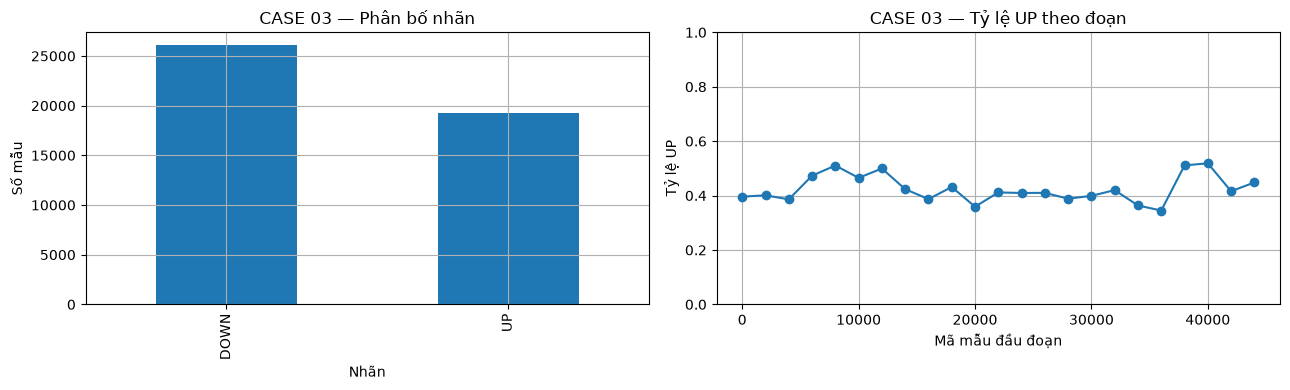

Nhận xét thực đo: tỷ lệ UP toàn tập 0.425; theo đoạn từ 0.345 đến 0.518. Giữ nguyên các giá trị lặp.


In [3]:
# Mô tả mất cân bằng nhãn và biến thiên theo thứ tự, không suy ra drift thật.
hinh, truc = plt.subplots(1, 2, figsize=(13, 4))
bang_du_lieu['Nhãn'].map({False:'DOWN', True:'UP'}).value_counts().plot.bar(ax=truc[0], title='CASE 03 — Phân bố nhãn')
truc[0].set(xlabel='Nhãn', ylabel='Số mẫu')
ty_le_doan = bang_du_lieu.groupby((bang_du_lieu['ma_mau']-1)//2000)['Nhãn'].mean()
truc[1].plot(ty_le_doan.index*2000+1, ty_le_doan.values, marker='o')
truc[1].set(title='CASE 03 — Tỷ lệ UP theo đoạn', xlabel='Mã mẫu đầu đoạn', ylabel='Tỷ lệ UP', ylim=(0,1))
plt.tight_layout(); plt.show()
print(f'Nhận xét thực đo: tỷ lệ UP toàn tập {bang_du_lieu["Nhãn"].mean():.3f}; theo đoạn từ {ty_le_doan.min():.3f} đến {ty_le_doan.max():.3f}. Giữ nguyên các giá trị lặp.')


## CASE 04 — Chia thời gian và hiệu chỉnh

**Mục tiêu:** khóa cấu hình trước đánh giá. **Đầu vào:** 45.312 mẫu. **Xử lý:** 1–10.000 huấn luyện, 10.001–20.000 hiệu chỉnh, phần còn lại đánh giá. Thử đúng ba tốc độ học, chấm mô hình giữ nguyên trên hiệu chỉnh; chọn accuracy cao nhất, hòa chọn ứng viên đầu. Sau chọn, huấn luyện mới trên toàn bộ 20.000 mẫu trước evaluation. **Đầu ra:** pipeline chung và cấu hình khóa. **Kiểm tra:** sao chép toàn bộ StandardScaler và LogisticRegression; detector rỗng, metric reset.

### CASE 04 — Sơ đồ phân chia thời gian

Trục ngang là mã mẫu; mỗi thanh là một giai đoạn liên tiếp có ghi ranh giới và số mẫu. Không có dấu drift/retrain. Chỉ phần giữa dùng chọn tốc độ học.

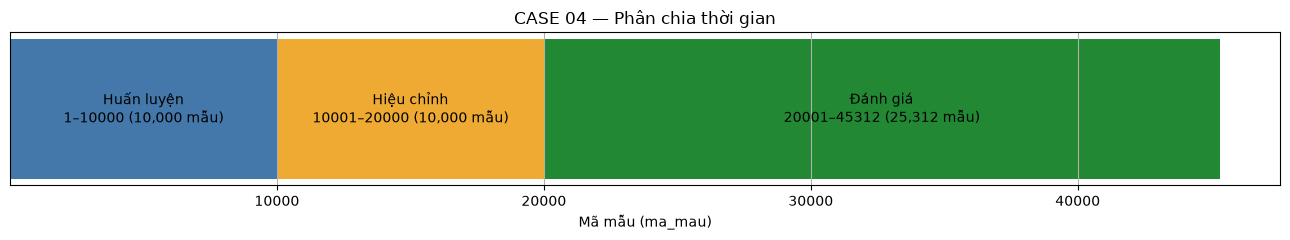

Nhận xét: đánh giá gồm 25,312 mẫu, bắt đầu sau toàn bộ dữ liệu chọn cấu hình.


,Giai đoạn,Số mẫu,ma_mau đầu,ma_mau cuối
0,Huấn luyện (train),10000,1,10000
1,Hiệu chỉnh (calibration),10000,10001,20000
2,Đánh giá (evaluation),25312,20001,45312


In [4]:
# Hiển thị ranh giới để kiểm tra các đoạn không chồng lấn.
moc_huan_luyen = cau_hinh['ket_thuc_huan_luyen']; moc_hieu_chinh = cau_hinh['ket_thuc_hieu_chinh']
hinh, truc = plt.subplots(figsize=(13, 2.5))
for dau, cuoi, ten, mau in [(1,moc_huan_luyen,'Huấn luyện','#4477aa'),(moc_huan_luyen+1,moc_hieu_chinh,'Hiệu chỉnh','#eeaa33'),(moc_hieu_chinh+1,len(du_lieu),'Đánh giá','#228833')]:
    truc.barh(0, cuoi-dau+1, left=dau, color=mau)
    truc.text((dau+cuoi)/2, 0, f'{ten}\n{dau}–{cuoi} ({cuoi-dau+1:,} mẫu)', ha='center', va='center')
truc.set(xlabel='Mã mẫu (ma_mau)', yticks=[], title='CASE 04 — Phân chia thời gian')
plt.tight_layout(); plt.show()
print(f'Nhận xét: đánh giá gồm {len(du_lieu)-moc_hieu_chinh:,} mẫu, bắt đầu sau toàn bộ dữ liệu chọn cấu hình.')

# Hiển thị phạm vi mã truy vết thực tế sau khi chia theo vị trí quan sát.
cac_giai_doan = [
    ('Huấn luyện (train)', 0, moc_huan_luyen),
    ('Hiệu chỉnh (calibration)', moc_huan_luyen, moc_hieu_chinh),
    ('Đánh giá (evaluation)', moc_hieu_chinh, len(du_lieu)),
]
bang_phan_chia = pd.DataFrame([
    {'Giai đoạn': ten, 'Số mẫu': cuoi - dau,
     'ma_mau đầu': int(ma_mau_goc[dau]), 'ma_mau cuối': int(ma_mau_goc[cuoi - 1])}
    for ten, dau, cuoi in cac_giai_doan
])
display(bang_phan_chia)


In [5]:
def tao_mo_hinh(toc_do):
    return preprocessing.StandardScaler() | linear_model.LogisticRegression(optimizer=optim.SGD(toc_do), l2=cau_hinh['l2'])

def huan_luyen(mo_hinh, cac_mau):
    for dac_trung, nhan in cac_mau:
        mo_hinh.learn_one(dac_trung, nhan)
    return mo_hinh

ket_qua_hieu_chinh = []
for toc_do in cau_hinh['toc_do_hoc_thu']:
    mo_hinh_thu = huan_luyen(tao_mo_hinh(toc_do), du_lieu[:moc_huan_luyen])
    dung = sum(mo_hinh_thu.predict_one(dac_trung) == nhan for dac_trung, nhan in du_lieu[moc_huan_luyen:moc_hieu_chinh])
    ket_qua_hieu_chinh.append({'Tốc độ học':toc_do, 'Accuracy hiệu chỉnh':dung/(moc_hieu_chinh-moc_huan_luyen)})
bang_hieu_chinh = pd.DataFrame(ket_qua_hieu_chinh)
toc_do_chon = float(bang_hieu_chinh.loc[bang_hieu_chinh['Accuracy hiệu chỉnh'].idxmax(), 'Tốc độ học'])
cau_hinh['toc_do_chon'] = toc_do_chon
cau_hinh_khoa = json.dumps(cau_hinh, sort_keys=True)
mo_hinh_chung = huan_luyen(tao_mo_hinh(toc_do_chon), du_lieu[:moc_hieu_chinh])
# Băm trạng thái dùng kiểm tra nhánh giữ nguyên, không ghi mô hình ra file.
import pickle
def bam_mo_hinh(mo_hinh):
    return hashlib.sha256(pickle.dumps(mo_hinh)).hexdigest()
bam_khoi_tao = bam_mo_hinh(mo_hinh_chung)
display(bang_hieu_chinh)
print('Tốc độ đã khóa:', toc_do_chon)


,Tốc độ học,Accuracy hiệu chỉnh
0,0.01,0.5045
1,0.05,0.4996
2,0.10,0.4997


Tốc độ đã khóa: 0.01


## CASE 05 — Baseline nhãn trước

**Mục tiêu:** đo lợi thế liên tục nhãn. **Đầu vào:** nhãn cuối trước evaluation và nhãn đã tiết lộ. **Xử lý:** dự đoán nhãn hiện tại bằng nhãn trước rồi mới đọc nhãn thật. **Đầu ra:** log accuracy tổng, tích lũy, cửa sổ. **Kiểm tra:** baseline chấm đủ cùng mẫu; không phải mô hình giữ nguyên.

In [6]:
cac_du_doan = []
def ghi_du_doan(ma_mau, phuong_an, nhan, du_doan, phien_ban_mo_hinh):
    cac_du_doan.append({'ma_mau':ma_mau, 'Phương án':phuong_an, 'Nhãn thật':nhan,
        'Dự đoán':du_doan, 'Lỗi':int(nhan != du_doan), 'Phiên bản':phien_ban_mo_hinh})
nhan_truoc = du_lieu[moc_hieu_chinh-1][1]
for ma_mau, (dac_trung, nhan) in zip(ma_mau_goc[moc_hieu_chinh:], du_lieu[moc_hieu_chinh:], strict=True):
    ghi_du_doan(ma_mau, 'Nhãn trước', nhan, nhan_truoc, None)
    nhan_truoc = nhan
print('Accuracy baseline:', 1-np.mean([dong['Lỗi'] for dong in cac_du_doan]))


Accuracy baseline: 0.8578144753476612


## CASE 06 — Mô hình tham chiếu và học từng mẫu

**Mục tiêu:** tách chính sách học. **Đầu vào:** bản sao pipeline chung. **Xử lý:** giữ nguyên hoàn toàn; nhánh học từng mẫu dự đoán → chấm → learn_one. **Đầu ra:** dự đoán và chuỗi lỗi tham chiếu từ nhánh giữ nguyên. **Kiểm tra:** trạng thái nhánh giữ nguyên không đổi sau dự đoán.

In [7]:
mo_hinh_giu_nguyen = copy.deepcopy(mo_hinh_chung)
mo_hinh_tung_mau = copy.deepcopy(mo_hinh_chung)
assert bam_mo_hinh(mo_hinh_giu_nguyen) == bam_khoi_tao
for ma_mau, (dac_trung, nhan) in zip(ma_mau_goc[moc_hieu_chinh:], du_lieu[moc_hieu_chinh:], strict=True):
    for ten, mo_hinh in [('Giữ nguyên', mo_hinh_giu_nguyen), ('Học từng mẫu', mo_hinh_tung_mau)]:
        du_doan = mo_hinh.predict_one(dac_trung)
        ghi_du_doan(ma_mau, ten, nhan, du_doan, 1)
        if ten == 'Học từng mẫu':
            mo_hinh.learn_one(dac_trung, nhan)
assert bam_mo_hinh(mo_hinh_giu_nguyen) == bam_khoi_tao
dong_tham_chieu = pd.DataFrame([dong for dong in cac_du_doan if dong['Phương án']=='Giữ nguyên'])
print('Accuracy tham chiếu:', 1-dong_tham_chieu['Lỗi'].mean())


Accuracy tham chiếu: 0.6513906447534766


## CASE 07 — Thực nghiệm A: ADWIN và DDM

**Mục tiêu:** cô lập hành vi detector. **Đầu vào:** cùng chuỗi lỗi giữ nguyên, 0 đúng / 1 sai. **Xử lý:** không thay mô hình; detector tự reset sau drift tại update tiếp theo, không reset thủ công. Warning ghi khi bắt đầu một đợt. **Đầu ra:** log sự kiện và bối cảnh lỗi. **Kiểm tra:** ADWIN hai chiều, so sánh trung bình cửa sổ giữ lại trước/sau cắt để chỉ báo chiều; đây là chẩn đoán, không phải mốc drift thật.

In [8]:
def tao_detector(ten):
    return drift.ADWIN(**cau_hinh['adwin']) if ten == 'ADWIN' else DDM(**cau_hinh['ddm'])
su_kien_a = []
bam_dong_loi_a = {}
for ten in ['ADWIN','DDM']:
    bo_phat_hien = tao_detector(ten)
    dang_warning = False
    loi_da_thay = []
    for dong in dong_tham_chieu.to_dict('records'):
        loi = dong['Lỗi']; loi_da_thay.append(loi)
        truoc = bo_phat_hien.estimation if ten == 'ADWIN' else np.nan
        bo_phat_hien.update(loi)
        loai = 'Drift' if bo_phat_hien.drift_detected else ('Warning' if getattr(bo_phat_hien,'warning_detected',False) else None)
        if loai == 'Drift' or (loai == 'Warning' and not dang_warning):
            sau = bo_phat_hien.estimation if ten == 'ADWIN' else np.nan
            su_kien_a.append({'ma_mau':dong['ma_mau'], 'Detector':ten, 'Loại sự kiện':loai,
                'Lỗi cửa sổ':np.mean(loi_da_thay[-cau_hinh['cua_so_metric']:]),
                'Ước lượng trước':truoc,'Ước lượng sau':sau,
                'Chiều':('Tăng' if sau>truoc else 'Giảm' if sau<truoc else 'Bằng') if ten=='ADWIN' else 'Không áp dụng'})
        dang_warning = loai == 'Warning'
    bam_dong_loi_a[ten] = hashlib.sha256(bytes(loi_da_thay)).hexdigest()
bang_su_kien_a = pd.DataFrame(su_kien_a, columns=['ma_mau','Detector','Loại sự kiện','Lỗi cửa sổ','Ước lượng trước','Ước lượng sau','Chiều'])
display(bang_su_kien_a)
display(bang_su_kien_a.groupby(['Detector','Loại sự kiện']).size().to_frame('Số sự kiện'))


,ma_mau,Detector,Loại sự kiện,Lỗi cửa sổ,Ước lượng trước,Ước lượng sau,Chiều
0,20256,ADWIN,Drift,0.515625,0.513725,0.562500,Tăng
1,20512,ADWIN,Drift,0.368000,0.211765,0.385417,Tăng
2,20608,ADWIN,Drift,0.390000,0.452632,0.337500,Giảm
3,20832,ADWIN,Drift,0.338000,0.376682,0.437500,Tăng
4,21152,ADWIN,Drift,0.234000,0.181818,0.152344,Giảm
...,...,...,...,...,...,...,...
302,45110,DDM,Warning,0.490000,NaN,NaN,Không áp dụng
303,45131,DDM,Drift,0.486000,NaN,NaN,Không áp dụng
304,45277,DDM,Warning,0.518000,NaN,NaN,Không áp dụng
305,45289,DDM,Warning,0.510000,NaN,NaN,Không áp dụng


Số sự kiện
Detector Loại sự kiện            
ADWIN    Drift                 57
DDM      Drift                 65
         Warning              185

### CASE 07 — Lỗi tham chiếu và sự kiện detector

Ba ô chung trục mã mẫu: tỷ lệ lỗi cửa sổ; dấu tam giác ADWIN; dấu tròn warning và tam giác drift DDM. Không có retrain trong A. ADWIN phát hiện thay đổi hai chiều nên cảnh báo không đồng nghĩa lỗi tăng.

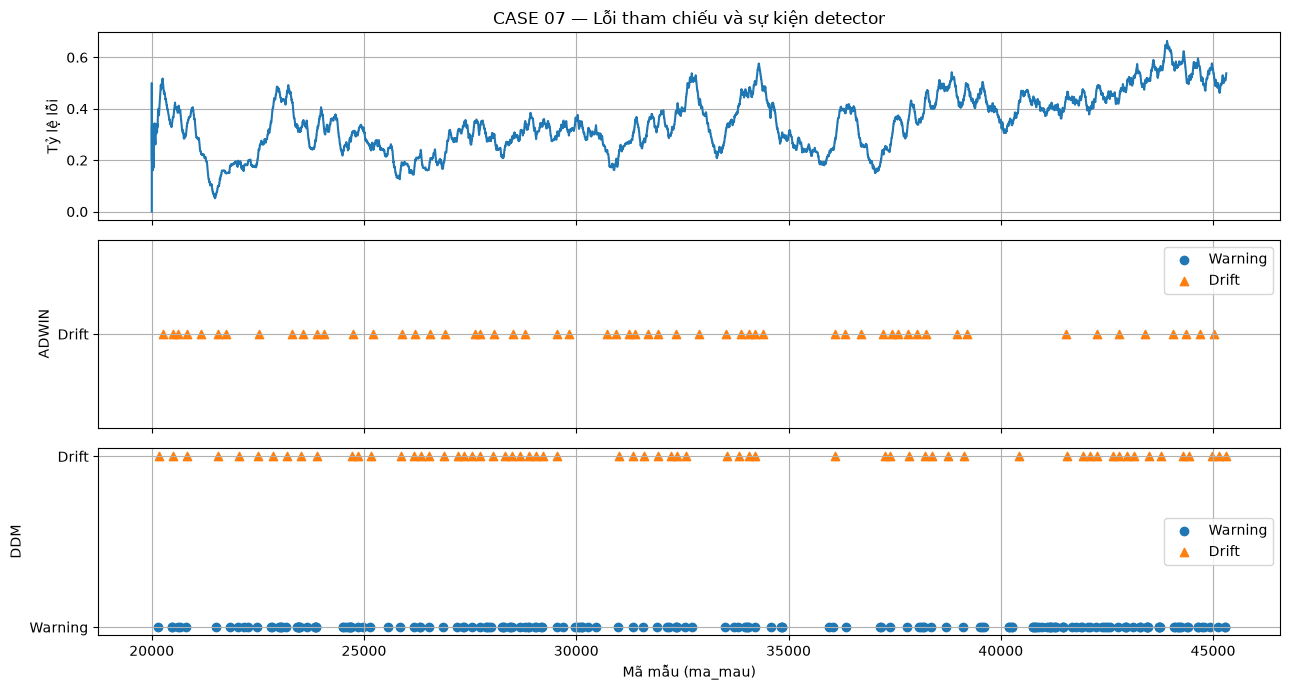

Nhận xét ADWIN: 57 drift; lỗi cửa sổ tại drift trung bình 0.353.
Nhận xét DDM: 65 drift; lỗi cửa sổ tại drift trung bình 0.361.
Chiều ADWIN tại drift: {'Tăng': 36, 'Giảm': 21}
Số lượng hoặc thời điểm cảnh báo không đủ để xếp hạng detector; không có mốc drift thật.
Số cảnh báo ADWIN có DDM trong phạm vi 500 mẫu: 56 / 57 ; chỉ đo mức gần nhau, không là độ trễ phát hiện.


In [9]:
# Đối chiếu cảnh báo với lỗi của cùng một mô hình giữ nguyên.
hinh, truc = plt.subplots(3,1,sharex=True,figsize=(13,7))
truc[0].plot(dong_tham_chieu['ma_mau'], dong_tham_chieu['Lỗi'].rolling(cau_hinh['cua_so_metric'],min_periods=1).mean())
truc[0].set(ylabel='Tỷ lệ lỗi',title='CASE 07 — Lỗi tham chiếu và sự kiện detector')
for vi_tri, ten in enumerate(['ADWIN','DDM'],1):
    for loai, dau in [('Warning','o'),('Drift','^')]:
        chon = bang_su_kien_a[(bang_su_kien_a['Detector']==ten)&(bang_su_kien_a['Loại sự kiện']==loai)]
        truc[vi_tri].scatter(chon['ma_mau'], [loai]*len(chon), marker=dau,label=loai)
    truc[vi_tri].set_ylabel(ten); truc[vi_tri].legend()
truc[-1].set_xlabel('Mã mẫu (ma_mau)'); plt.tight_layout(); plt.show()
for ten in ['ADWIN','DDM']:
    chon = bang_su_kien_a[(bang_su_kien_a['Detector']==ten)&(bang_su_kien_a['Loại sự kiện']=='Drift')]
    print(f'Nhận xét {ten}: {len(chon)} drift; lỗi cửa sổ tại drift trung bình {chon["Lỗi cửa sổ"].mean():.3f}.')
print('Chiều ADWIN tại drift:', bang_su_kien_a.query('Detector == "ADWIN"')['Chiều'].value_counts().to_dict())
print('Số lượng hoặc thời điểm cảnh báo không đủ để xếp hạng detector; không có mốc drift thật.')

ma_adwin = bang_su_kien_a.query('Detector == "ADWIN" and `Loại sự kiện` == "Drift"')['ma_mau'].to_numpy()
ma_ddm = bang_su_kien_a.query('Detector == "DDM" and `Loại sự kiện` == "Drift"')['ma_mau'].to_numpy()
if len(ma_adwin) and len(ma_ddm):
    khoang_cach = [min(abs(ma_ddm-ma)) for ma in ma_adwin]
    print('Số cảnh báo ADWIN có DDM trong phạm vi 500 mẫu:', sum(khoang<=500 for khoang in khoang_cach), '/', len(ma_adwin), '; chỉ đo mức gần nhau, không là độ trễ phát hiện.')


## CASE 08 — Định nghĩa chính sách retrain

**Mục tiêu:** cùng quy trình cập nhật cho hai detector. **Đầu vào:** pipeline chung, buffer tiền evaluation tối đa 2.000 mẫu đã có nhãn. **Xử lý:** dự đoán → chấm → thêm buffer → detector nhận lỗi → kiểm tra ít nhất 1.000 mẫu và chờ ít nhất 1.000 mẫu từ đầu evaluation hoặc retrain trước → huấn luyện mới cả scaler và classifier trên buffer. **Đầu ra:** phiên bản mới dùng từ mẫu kế; log warning, drift, retrain, hoãn riêng. **Kiểm tra:** nếu retrain thành công thay detector bằng đối tượng rỗng ngay; detector mới chưa có cờ drift nên không tự reset lần hai. Nếu hoãn, để API tự reset ở update sau. Warning không kích hoạt retrain. Thời gian retrain gồm tạo pipeline và learn_one, không gồm phát hiện và ghi log.

## CASE 09 — Thực nghiệm B: các chính sách cập nhật

**Mục tiêu:** so sánh năm nhánh trên cùng evaluation. **Đầu vào:** baseline và hai nhánh đã chạy, hai bản sao pipeline adaptive. **Xử lý:** mỗi detector chỉ nhận lỗi mô hình của chính nó. **Đầu ra:** bảng dự đoán và sự kiện trong bộ nhớ. **Kiểm tra:** cùng mã mẫu; số cảnh báo B không cô lập chất lượng detector do chuỗi lỗi khác nhau.

In [10]:
def ly_do_hoan_retrain(so_mau, ma_mau, lan_cuoi, cau_hinh_chay):
    ly_do = []
    if so_mau < cau_hinh_chay['toi_thieu_retrain']: ly_do.append('Chưa đủ mẫu')
    if ma_mau-lan_cuoi < cau_hinh_chay['khoang_cho']: ly_do.append('Chưa đủ khoảng chờ')
    return ly_do

def chay_nhanh_adaptive(ten, cac_mau, mo_hinh_dau, bo_dem_dau, moc_dau, tao_bo_phat_hien, cau_hinh_chay, cac_ma_mau=None):
    # Một đường xử lý dùng chung cho benchmark và kiểm thử logic riêng trong bộ nhớ.
    du_doan_nhanh = []; su_kien_nhanh = []
    mo_hinh = copy.deepcopy(mo_hinh_dau); bo_phat_hien = tao_bo_phat_hien()
    assert bam_mo_hinh(mo_hinh) == bam_mo_hinh(mo_hinh_dau)
    assert mo_hinh is not mo_hinh_dau
    bo_dem = deque(bo_dem_dau, maxlen=cau_hinh_chay['buffer_retrain'])
    phien_ban_mo_hinh = 1; lan_cuoi = moc_dau; dang_warning = False
    # Benchmark nhận mã gốc; chỉ bài kiểm thử riêng không truyền mã mới dùng mã cục bộ.
    if cac_ma_mau is None:
        cac_ma_mau = range(moc_dau + 1, moc_dau + 1 + len(cac_mau))
    for ma_mau, (dac_trung, nhan) in zip(cac_ma_mau, cac_mau, strict=True):
        du_doan = mo_hinh.predict_one(dac_trung)
        du_doan_nhanh.append({'ma_mau':ma_mau,'Phương án':ten,'Nhãn thật':nhan,'Dự đoán':du_doan,'Lỗi':int(nhan!=du_doan),'Phiên bản':phien_ban_mo_hinh})
        bo_dem.append((ma_mau,dac_trung,nhan))
        bo_phat_hien.update(int(nhan != du_doan))
        loai = 'Drift' if bo_phat_hien.drift_detected else ('Warning' if getattr(bo_phat_hien,'warning_detected',False) else None)
        su_kien = {'ma_mau':ma_mau,'Phương án':ten,'Detector':ten,'Phiên bản cũ':phien_ban_mo_hinh,
            'Phiên bản mới':phien_ban_mo_hinh,'Đầu retrain':None,'Cuối retrain':None,'Số mẫu retrain':None,
            'Thời gian retrain':None,'Lý do hoãn':None}
        if loai == 'Drift' or (loai=='Warning' and not dang_warning):
            su_kien_nhanh.append(dict(su_kien, **{'Loại sự kiện':loai}))
        dang_warning = loai == 'Warning'
        if loai == 'Drift':
            ly_do = ly_do_hoan_retrain(len(bo_dem), ma_mau, lan_cuoi, cau_hinh_chay)
            if ly_do:
                su_kien_nhanh.append(dict(su_kien, **{'Loại sự kiện':'Hoãn retrain','Lý do hoãn':'; '.join(ly_do)}))
            else:
                bat_dau = time.perf_counter()
                mo_hinh = huan_luyen(tao_mo_hinh(toc_do_chon), [(dac,nh) for ma,dac,nh in bo_dem])
                thoi_gian = time.perf_counter()-bat_dau
                phien_ban_mo_hinh += 1; lan_cuoi = ma_mau
                su_kien_nhanh.append(dict(su_kien, **{'Loại sự kiện':'Retrain','Phiên bản mới':phien_ban_mo_hinh,
                    'Đầu retrain':bo_dem[0][0],'Cuối retrain':bo_dem[-1][0],
                    'Số mẫu retrain':len(bo_dem),'Thời gian retrain':thoi_gian}))
                bo_phat_hien = tao_bo_phat_hien(); dang_warning = False
    return du_doan_nhanh, su_kien_nhanh

su_kien_b = []
bo_dem_dau = [(ma_mau_goc[vi_tri],*du_lieu[vi_tri]) for vi_tri in range(max(0,moc_hieu_chinh-cau_hinh['buffer_retrain']),moc_hieu_chinh)]
for ten in ['ADWIN','DDM']:
    du_doan_nhanh, su_kien_nhanh = chay_nhanh_adaptive(ten,du_lieu[moc_hieu_chinh:],mo_hinh_chung,bo_dem_dau,moc_hieu_chinh,lambda:tao_detector(ten),cau_hinh,cac_ma_mau=ma_mau_goc[moc_hieu_chinh:])
    cac_du_doan.extend(du_doan_nhanh); su_kien_b.extend(su_kien_nhanh)
bang_du_doan = pd.DataFrame(cac_du_doan).sort_values(['Phương án','ma_mau']).reset_index(drop=True)
bang_du_doan['Accuracy tích lũy'] = bang_du_doan.groupby('Phương án')['Lỗi'].transform(lambda cot:1-cot.expanding().mean())
bang_du_doan['Accuracy cửa sổ'] = bang_du_doan.groupby('Phương án')['Lỗi'].transform(lambda cot:1-cot.rolling(cau_hinh['cua_so_metric'],min_periods=1).mean())
bang_su_kien = pd.DataFrame(su_kien_b, columns=['ma_mau','Phương án','Detector','Phiên bản cũ','Phiên bản mới','Đầu retrain','Cuối retrain','Số mẫu retrain','Thời gian retrain','Lý do hoãn','Loại sự kiện'])
display(bang_du_doan.head()); display(bang_su_kien)
print('Các bảng chỉ nằm trong bộ nhớ. Cửa sổ metric đầu evaluation ngắn hơn 500 mẫu.')


,ma_mau,Phương án,Nhãn thật,Dự đoán,Lỗi,Phiên bản,Accuracy tích lũy,Accuracy cửa sổ
0,20001,ADWIN,False,False,0,1.0,1.000000,1.000000
1,20002,ADWIN,True,False,1,1.0,0.500000,0.500000
2,20003,ADWIN,False,False,0,1.0,0.666667,0.666667
3,20004,ADWIN,False,False,0,1.0,0.750000,0.750000
4,20005,ADWIN,False,False,0,1.0,0.800000,0.800000


,ma_mau,Phương án,Detector,Phiên bản cũ,Phiên bản mới,Đầu retrain,Cuối retrain,Số mẫu retrain,Thời gian retrain,Lý do hoãn,Loại sự kiện
0,20256,ADWIN,ADWIN,1,1,NaN,NaN,NaN,NaN,None,Drift
1,20256,ADWIN,ADWIN,1,1,NaN,NaN,NaN,NaN,Chưa đủ khoảng chờ,Hoãn retrain
2,20512,ADWIN,ADWIN,1,1,NaN,NaN,NaN,NaN,None,Drift
3,20512,ADWIN,ADWIN,1,1,NaN,NaN,NaN,NaN,Chưa đủ khoảng chờ,Hoãn retrain
4,20608,ADWIN,ADWIN,1,1,NaN,NaN,NaN,NaN,None,Drift
...,...,...,...,...,...,...,...,...,...,...,...
412,44676,DDM,DDM,18,18,NaN,NaN,NaN,NaN,None,Drift
413,44676,DDM,DDM,18,18,NaN,NaN,NaN,NaN,Chưa đủ khoảng chờ,Hoãn retrain
414,45005,DDM,DDM,18,18,NaN,NaN,NaN,NaN,None,Warning
415,45011,DDM,DDM,18,18,NaN,NaN,NaN,NaN,None,Drift


Các bảng chỉ nằm trong bộ nhớ. Cửa sổ metric đầu evaluation ngắn hơn 500 mẫu.


## CASE 10 — Trực quan hóa kết quả

**Mục tiêu:** xem chất lượng theo thời gian và chi phí. **Đầu vào:** bảng đo trực tiếp. **Xử lý:** màu cố định, chung trục mã mẫu cho biểu đồ thời gian. **Đầu ra:** năm biểu đồ. **Kiểm tra:** sự kiện chỉ vẽ điểm tại nơi có thật; không nối dữ liệu không tồn tại.

In [11]:
thu_tu = ['Nhãn trước','Giữ nguyên','Học từng mẫu','ADWIN','DDM']
mau_sac = dict(zip(thu_tu,['#777777','#000000','#4477aa','#228833','#cc6677']))
bang_rong = bang_du_doan.pivot(index='ma_mau',columns='Phương án',values='Accuracy cửa sổ')


### CASE 10 — Biểu đồ 1: Accuracy cửa sổ

Trục ngang là mã mẫu evaluation, trục dọc là accuracy (0–1); mỗi màu là một phương án, không có dấu sự kiện tại biểu đồ này. Cửa sổ chỉ dùng tối đa 500 mẫu đã chấm, không dùng tương lai.

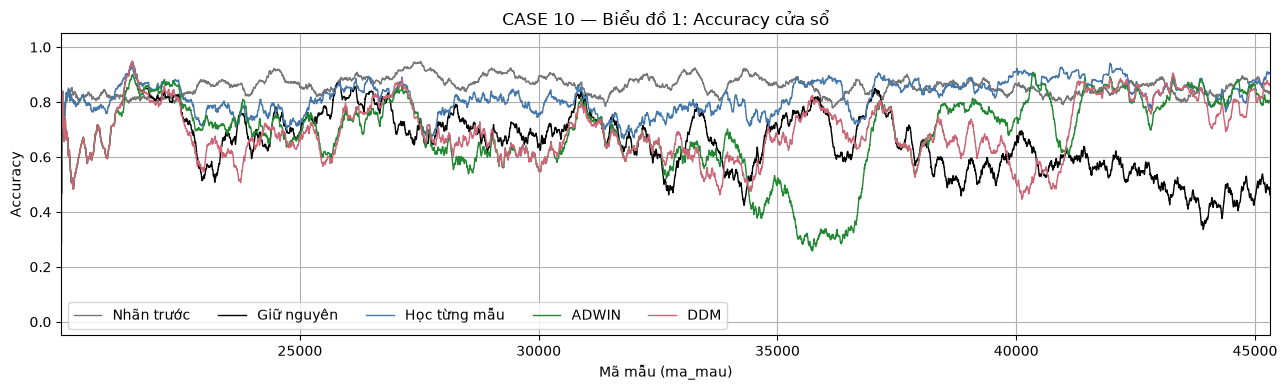

Nhận xét Nhãn trước: giá trị cuối 0.8300; thấp nhất 0.0000.
Nhận xét Giữ nguyên: giá trị cuối 0.4620; thấp nhất 0.3360.
Nhận xét Học từng mẫu: giá trị cuối 0.9040; thấp nhất 0.5000.
Nhận xét ADWIN: giá trị cuối 0.8020; thấp nhất 0.2580.
Nhận xét DDM: giá trị cuối 0.8620; thấp nhất 0.4460.


In [12]:
# So sánh accuracy cửa sổ từ bảng dự đoán đã ghi.
hinh, truc = plt.subplots()
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    truc.plot(chon['ma_mau'], chon['Accuracy cửa sổ'], color=mau_sac[ten], label=ten, linewidth=1)
truc.set(xlabel='Mã mẫu (ma_mau)',ylabel='Accuracy',title='CASE 10 — Biểu đồ 1: Accuracy cửa sổ',xlim=(moc_hieu_chinh+1,len(du_lieu)))
truc.legend(ncol=5); plt.tight_layout(); plt.show()
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    print(f'Nhận xét {ten}: giá trị cuối {chon["Accuracy cửa sổ"].iloc[-1]:.4f}; thấp nhất {chon["Accuracy cửa sổ"].min():.4f}.')


### CASE 10 — Biểu đồ 2: Accuracy tích lũy

Trục ngang là mã mẫu evaluation, trục dọc là accuracy (0–1); mỗi màu là một phương án, không có dấu sự kiện tại biểu đồ này. Chỉ số tích lũy có thể che khuất suy giảm gần đây; cần đọc cùng biểu đồ cửa sổ.

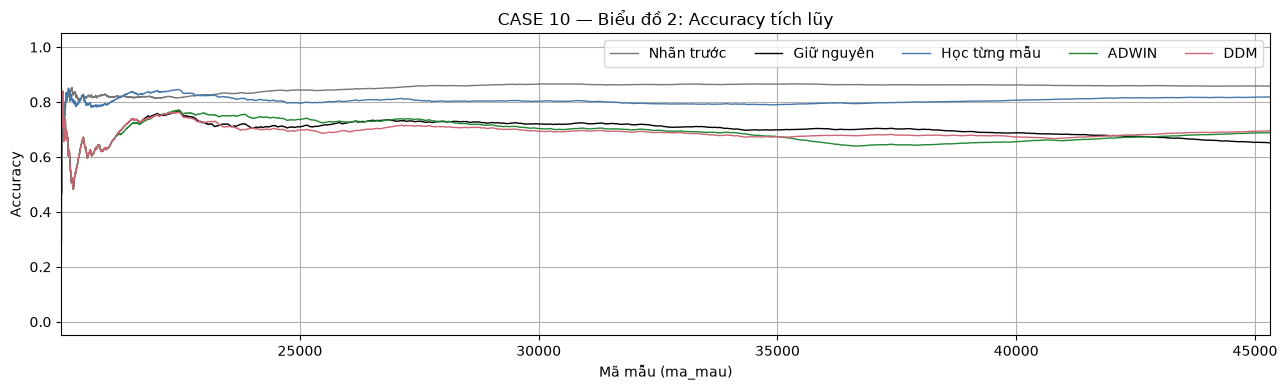

Nhận xét Nhãn trước: giá trị cuối 0.8578; thấp nhất 0.0000.
Nhận xét Giữ nguyên: giá trị cuối 0.6514; thấp nhất 0.4825.
Nhận xét Học từng mẫu: giá trị cuối 0.8185; thấp nhất 0.5000.
Nhận xét ADWIN: giá trị cuối 0.6885; thấp nhất 0.4825.
Nhận xét DDM: giá trị cuối 0.6954; thấp nhất 0.4825.


In [13]:
# So sánh accuracy tích lũy từ bảng dự đoán đã ghi.
hinh, truc = plt.subplots()
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    truc.plot(chon['ma_mau'], chon['Accuracy tích lũy'], color=mau_sac[ten], label=ten, linewidth=1)
truc.set(xlabel='Mã mẫu (ma_mau)',ylabel='Accuracy',title='CASE 10 — Biểu đồ 2: Accuracy tích lũy',xlim=(moc_hieu_chinh+1,len(du_lieu)))
truc.legend(ncol=5); plt.tight_layout(); plt.show()
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    print(f'Nhận xét {ten}: giá trị cuối {chon["Accuracy tích lũy"].iloc[-1]:.4f}; thấp nhất {chon["Accuracy tích lũy"].min():.4f}.')


### CASE 10 — Biểu đồ 3: Timeline drift và retrain

Trục ngang mã mẫu giống biểu đồ accuracy; trục dọc là nhánh adaptive. Tam giác là drift, sao là retrain, vòng tròn rỗng là warning và dấu x là hoãn. Drift và retrain cùng mẫu có độ lệch dọc nhỏ để thấy cả hai; không nối các sự kiện.

Nhận xét ADWIN: Warning có 0 sự kiện.
Nhận xét ADWIN: Drift có 45 sự kiện.
Nhận xét ADWIN: Retrain có 17 sự kiện.
Nhận xét ADWIN: Hoãn retrain có 28 sự kiện.
Nhận xét DDM: Warning có 203 sự kiện.
Nhận xét DDM: Drift có 62 sự kiện.
Nhận xét DDM: Retrain có 17 sự kiện.
Nhận xét DDM: Hoãn retrain có 45 sự kiện.


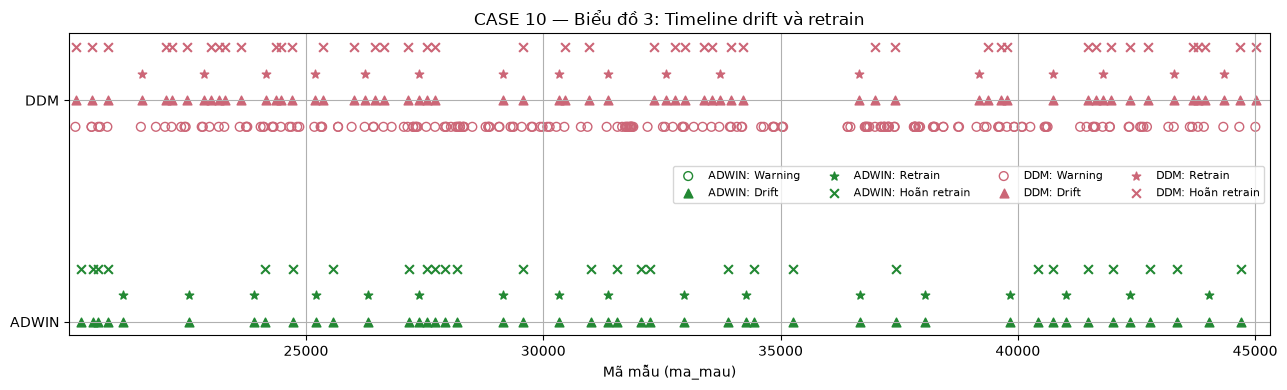

In [14]:
# Tách sự kiện phát hiện và hành động huấn luyện thực sự.
hinh, truc = plt.subplots()
for vi_tri, ten in enumerate(['ADWIN','DDM']):
    for do_lech, loai, dau in [(-.12,'Warning','o'),(0,'Drift','^'),(.12,'Retrain','*'),(.24,'Hoãn retrain','x')]:
        chon = bang_su_kien[(bang_su_kien['Phương án']==ten)&(bang_su_kien['Loại sự kiện']==loai)]
        truc.scatter(chon['ma_mau'],np.full(len(chon),vi_tri+do_lech),marker=dau, **({'facecolors':'none','edgecolors':mau_sac[ten]} if loai=='Warning' else {'color':mau_sac[ten]}),label=f'{ten}: {loai}',s=40)
        print(f'Nhận xét {ten}: {loai} có {len(chon)} sự kiện.')
truc.set(yticks=[0,1],yticklabels=['ADWIN','DDM'],xlabel='Mã mẫu (ma_mau)',title='CASE 10 — Biểu đồ 3: Timeline drift và retrain',xlim=(moc_hieu_chinh+1,len(du_lieu)))
truc.legend(ncol=4,fontsize=8); plt.tight_layout(); plt.show()


### CASE 10 — Biểu đồ 4: Chênh lệch accuracy cửa sổ

Trục ngang mã mẫu; trục dọc là điểm phần trăm so với giữ nguyên. Dương nghĩa adaptive cao hơn, âm thấp hơn. Đường 0 là ngang bằng. Sự kiện xem tại biểu đồ 3 trên cùng trục thời gian.

Nhận xét ADWIN: 50.55% vị trí có chênh lệch dương; cuối đoạn 34.00 điểm phần trăm.
Nhận xét DDM: 45.42% vị trí có chênh lệch dương; cuối đoạn 40.00 điểm phần trăm.


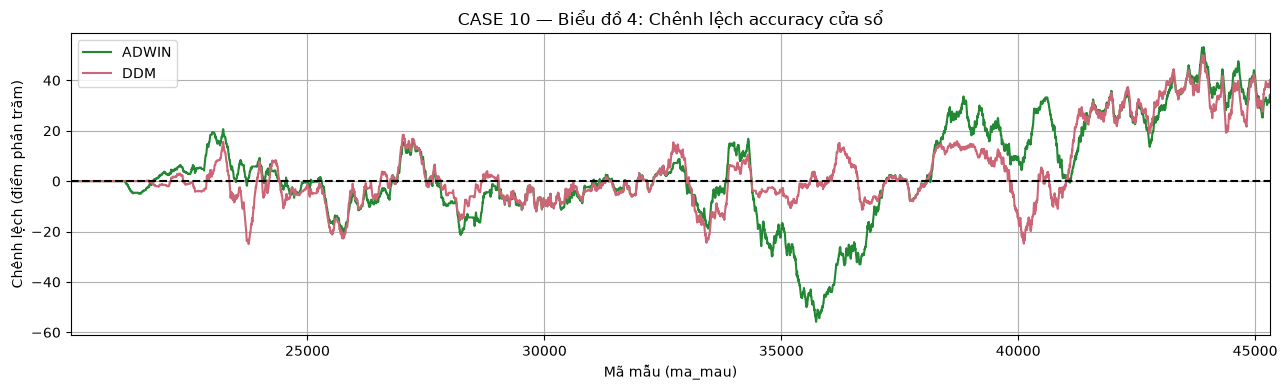

In [15]:
# Đo chênh lệch trên cùng cửa sổ và cùng các mẫu.
hinh, truc = plt.subplots()
for ten in ['ADWIN','DDM']:
    chenh_lech = 100*(bang_rong[ten]-bang_rong['Giữ nguyên'])
    truc.plot(chenh_lech.index,chenh_lech,color=mau_sac[ten],label=ten)
    print(f'Nhận xét {ten}: {100*(chenh_lech>0).mean():.2f}% vị trí có chênh lệch dương; cuối đoạn {chenh_lech.iloc[-1]:.2f} điểm phần trăm.')
truc.axhline(0,color='black',linestyle='--'); truc.legend()
truc.set(xlabel='Mã mẫu (ma_mau)',ylabel='Chênh lệch (điểm phần trăm)',title='CASE 10 — Biểu đồ 4: Chênh lệch accuracy cửa sổ',xlim=(moc_hieu_chinh+1,len(du_lieu)))
plt.tight_layout(); plt.show()


### CASE 10 — Biểu đồ 5: Chất lượng và chi phí

Ba ô riêng: accuracy (%), số retrain, tổng giây retrain; trục ngang là phương án. Nhánh không retrain không có cột chi phí áp dụng. Không gộp khác đơn vị và không có dấu thời gian sự kiện ở biểu đồ tổng hợp.

Nhận xét ADWIN: Số lần retrain = 17.0000.
Nhận xét DDM: Số lần retrain = 17.0000.
Nhận xét ADWIN: Thời gian (giây) = 0.7534.
Nhận xét DDM: Thời gian (giây) = 0.7758.


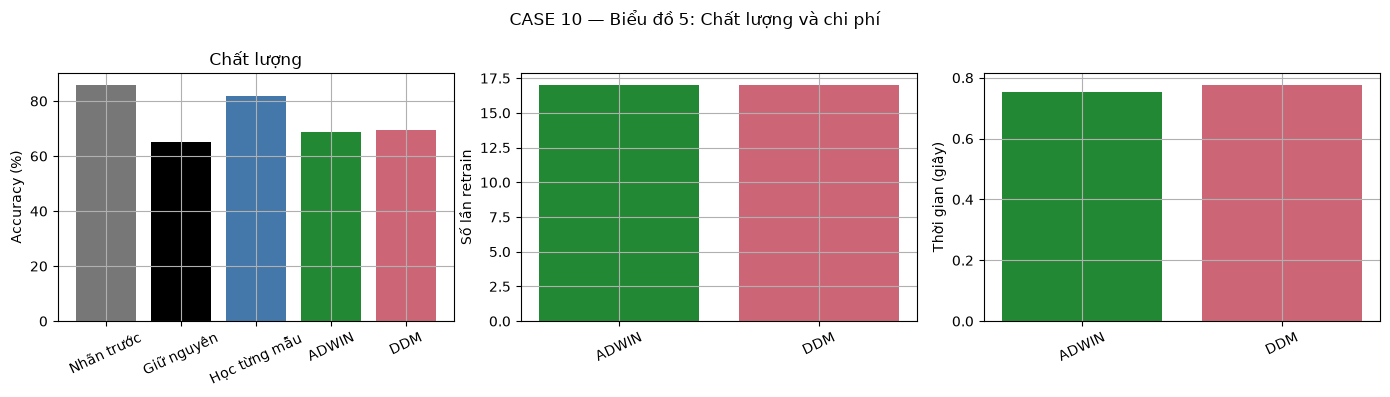

Thời gian này chỉ tính retrain, không phải tổng chi phí inference, detector hay học từng mẫu.


In [16]:
# Tách đơn vị chất lượng, số lần và thời gian huấn luyện lại.
hinh, truc = plt.subplots(1,3,figsize=(14,4))
chat_luong = [100*(1-bang_du_doan.query('`Phương án` == @ten')['Lỗi'].mean()) for ten in thu_tu]
truc[0].bar(thu_tu,chat_luong,color=[mau_sac[ten] for ten in thu_tu]); truc[0].set(ylabel='Accuracy (%)',title='Chất lượng')
for vi_tri, cot, don_vi in [(1,None,'Số lần retrain'),(2,'Thời gian retrain','Thời gian (giây)')]:
    for ten in ['ADWIN','DDM']:
        chon = bang_su_kien[(bang_su_kien['Phương án']==ten)&(bang_su_kien['Loại sự kiện']=='Retrain')]
        gia_tri = len(chon) if cot is None else chon[cot].sum()
        truc[vi_tri].bar(ten,gia_tri,color=mau_sac[ten])
        print(f'Nhận xét {ten}: {don_vi} = {gia_tri:.4f}.')
    truc[vi_tri].set_ylabel(don_vi)
for mot_truc in truc: mot_truc.tick_params(axis='x',rotation=25)
hinh.suptitle('CASE 10 — Biểu đồ 5: Chất lượng và chi phí'); plt.tight_layout(); plt.show()
print('Thời gian này chỉ tính retrain, không phải tổng chi phí inference, detector hay học từng mẫu.')


## CASE 11 — Bảng so sánh và phân tích sau cập nhật

**Mục tiêu:** lượng hóa lợi ích, chi phí và từng phiên bản. **Đầu vào:** log dự đoán/sự kiện. **Xử lý:** balanced accuracy là trung bình recall hai nhãn; chênh lệch theo điểm phần trăm. Trước/sau tối đa 500 mẫu, cắt sau tại retrain tiếp theo và cắt trước tại lần retrain trước để không trộn phiên bản. **Đầu ra:** bảng tổng hợp và bảng từng retrain. **Kiểm tra:** so sánh giữ nguyên trên chính đoạn sau; trước/sau khác thời gian nên không là bằng chứng nhân quả.

In [17]:
accuracy_theo_nhanh = bang_du_doan.groupby('Phương án')['Lỗi'].mean().rsub(1)
cac_tong_hop = []
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    cac_recall = [((nhom['Dự đoán']==nhan).mean()) for nhan,nhom in chon.groupby('Nhãn thật')]
    su_kien = bang_su_kien[bang_su_kien['Phương án']==ten]
    retrain = su_kien[su_kien['Loại sự kiện']=='Retrain']
    cac_tong_hop.append({'Phương án':ten,'Số mẫu được chấm':len(chon),'Accuracy':accuracy_theo_nhanh[ten],
        'Balanced accuracy':np.mean(cac_recall),'Chênh với baseline (đpt)':100*(accuracy_theo_nhanh[ten]-accuracy_theo_nhanh['Nhãn trước']),
        'Chênh với giữ nguyên (đpt)':100*(accuracy_theo_nhanh[ten]-accuracy_theo_nhanh['Giữ nguyên']),
        'Số warning':len(su_kien[su_kien['Loại sự kiện']=='Warning']) if ten == 'DDM' else 'Không áp dụng',
        'Số hoãn retrain':len(su_kien[su_kien['Loại sự kiện']=='Hoãn retrain']) if ten in ['ADWIN','DDM'] else 'Không áp dụng',
        'Số drift':len(su_kien[su_kien['Loại sự kiện']=='Drift']) if ten in ['ADWIN','DDM'] else 'Không áp dụng',
        'Số retrain':len(retrain) if ten in ['ADWIN','DDM'] else 'Không áp dụng',
        'Tổng thời gian retrain (giây)':retrain['Thời gian retrain'].sum() if ten in ['ADWIN','DDM'] else 'Không áp dụng'})
bang_tong_hop = pd.DataFrame(cac_tong_hop)
cac_phan_tich = []
for ten in ['ADWIN','DDM']:
    retrain = bang_su_kien[(bang_su_kien['Phương án']==ten)&(bang_su_kien['Loại sự kiện']=='Retrain')].sort_values('ma_mau').to_dict('records')
    for vi_tri, dong in enumerate(retrain):
        ma = dong['ma_mau']; cua_so = cau_hinh['cua_so_phan_tich']
        dau = max(moc_hieu_chinh+1,ma-cua_so+1, retrain[vi_tri-1]['ma_mau']+1 if vi_tri else moc_hieu_chinh+1)
        cuoi = min(len(du_lieu),ma+cua_so,retrain[vi_tri+1]['ma_mau'] if vi_tri+1<len(retrain) else len(du_lieu))
        truoc = bang_du_doan[(bang_du_doan['Phương án']==ten)&bang_du_doan['ma_mau'].between(dau,ma)]
        sau = bang_du_doan[(bang_du_doan['Phương án']==ten)&bang_du_doan['ma_mau'].between(ma+1,cuoi)]
        giu_nguyen = bang_du_doan[(bang_du_doan['Phương án']=='Giữ nguyên')&bang_du_doan['ma_mau'].between(ma+1,cuoi)]
        accuracy_sau = 1-sau['Lỗi'].mean(); accuracy_giu = 1-giu_nguyen['Lỗi'].mean()
        cac_phan_tich.append({'ma_mau':ma,'Detector':ten,'Phiên bản mới':dong['Phiên bản mới'],
            'Số mẫu trước':len(truoc),'Số mẫu sau':len(sau),'Accuracy trước':1-truoc['Lỗi'].mean(),
            'Accuracy sau':accuracy_sau,'Accuracy giữ nguyên cùng đoạn sau':accuracy_giu,
            'Chênh với giữ nguyên (đpt)':100*(accuracy_sau-accuracy_giu),
            'Tình trạng':'Đủ cửa sổ' if min(len(truoc),len(sau))==cua_so else 'Không đủ cửa sổ 500 mẫu'})
bang_phan_tich = pd.DataFrame(cac_phan_tich, columns=['ma_mau','Detector','Phiên bản mới','Số mẫu trước','Số mẫu sau','Accuracy trước','Accuracy sau','Accuracy giữ nguyên cùng đoạn sau','Chênh với giữ nguyên (đpt)','Tình trạng'])
display(bang_tong_hop); display(bang_phan_tich)
for ten in ['ADWIN','DDM']:
    chon = bang_phan_tich[bang_phan_tich['Detector']==ten]
    print(f'Nhận xét {ten}: {len(chon)} retrain; {(chon["Chênh với giữ nguyên (đpt)"]>0).sum()} đoạn sau cao hơn giữ nguyên, {(chon["Chênh với giữ nguyên (đpt)"]<0).sum()} đoạn thấp hơn. Không suy ra retrain luôn giúp.')


,Phương án,Số mẫu được chấm,Accuracy,Balanced accuracy,Chênh với baseline (đpt),Chênh với giữ nguyên (đpt),Số warning,Số hoãn retrain,Số drift,Số retrain,Tổng thời gian retrain (giây)
0,Nhãn trước,25312,0.857814,0.853535,0.000000,20.642383,Không áp dụng,Không áp dụng,Không áp dụng,Không áp dụng,Không áp dụng
1,Giữ nguyên,25312,0.651391,0.649194,-20.642383,0.000000,Không áp dụng,Không áp dụng,Không áp dụng,Không áp dụng,Không áp dụng
2,Học từng mẫu,25312,0.818505,0.805445,-3.930942,16.711441,Không áp dụng,Không áp dụng,Không áp dụng,Không áp dụng,Không áp dụng
3,ADWIN,25312,0.688488,0.679925,-16.932680,3.709703,Không áp dụng,28,45,17,0.75338
4,DDM,25312,0.695441,0.673471,-16.237358,4.405025,203,45,62,17,0.775809


,ma_mau,Detector,Phiên bản mới,Số mẫu trước,Số mẫu sau,Accuracy trước,Accuracy sau,Accuracy giữ nguyên cùng đoạn sau,Chênh với giữ nguyên (đpt),Tình trạng
0,21152,ADWIN,2,500,500,0.766,0.820,0.842,-2.2,Đủ cửa sổ
1,22528,ADWIN,3,500,500,0.788,0.750,0.556,19.4,Đủ cửa sổ
2,23904,ADWIN,4,500,500,0.734,0.702,0.702,0.0,Đủ cửa sổ
3,25216,ADWIN,5,500,500,0.744,0.650,0.828,-17.8,Đủ cửa sổ
4,26304,ADWIN,6,500,500,0.686,0.818,0.800,1.8,Đủ cửa sổ
5,27392,ADWIN,7,500,500,0.760,0.636,0.722,-8.6,Đủ cửa sổ
6,29152,ADWIN,8,500,500,0.582,0.638,0.668,-3.0,Đủ cửa sổ
7,30336,ADWIN,9,500,500,0.598,0.794,0.826,-3.2,Đủ cửa sổ
8,31360,ADWIN,10,500,500,0.694,0.612,0.670,-5.8,Đủ cửa sổ
9,32960,ADWIN,11,500,500,0.638,0.560,0.746,-18.6,Đủ cửa sổ


Nhận xét ADWIN: 17 retrain; 7 đoạn sau cao hơn giữ nguyên, 9 đoạn thấp hơn. Không suy ra retrain luôn giúp.
Nhận xét DDM: 17 retrain; 8 đoạn sau cao hơn giữ nguyên, 9 đoạn thấp hơn. Không suy ra retrain luôn giúp.


## CASE 12 — Kiểm tra tính đúng và khả năng tái lập

**Mục tiêu:** kiểm tra bất biến sau toàn bộ thí nghiệm. **Đầu vào:** cấu hình khóa và log. **Xử lý:** assert thứ tự, tập mẫu, hash mô hình, phiên bản, phạm vi huấn luyện và metric. **Đầu ra:** bảng kiểm tra. **Kiểm tra:** chạy lại từ kernel mới; số liệu chất lượng phải tái lập, thời gian có thể khác. Không có ground truth drift nên không tính precision/recall hay độ trễ detector.

In [18]:
kiem_tra = []
def xac_nhan(dieu_kien, mo_ta):
    assert dieu_kien, mo_ta
    kiem_tra.append({'Kiểm tra':mo_ta,'Kết quả':'Đạt'})
xac_nhan(cau_hinh_khoa == json.dumps(cau_hinh,sort_keys=True), 'Cấu hình không đổi sau khóa')
xac_nhan(bang_du_lieu.drop(columns=['ma_mau','Nhãn']).to_dict('records') == [dac_trung for dac_trung, nhan in du_lieu], 'Giữ nguyên thứ tự mẫu River; không shuffle hoặc sắp xếp theo date')
xac_nhan(bam_mo_hinh(mo_hinh_giu_nguyen)==bam_khoi_tao, 'Giữ nguyên cả mô hình và preprocessing')
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    xac_nhan(np.array_equal(chon['ma_mau'],ma_mau_goc[moc_hieu_chinh:]),f'{ten}: đúng cùng mẫu, thứ tự liên tiếp')
    xac_nhan(np.isclose(1-chon['Lỗi'].mean(),chon['Accuracy tích lũy'].iloc[-1]),f'{ten}: accuracy khớp lỗi')
    xac_nhan(np.array_equal(chon['Lỗi'],(chon['Nhãn thật']!=chon['Dự đoán']).astype(int)),f'{ten}: lỗi khớp dự đoán')
for ten in ['ADWIN','DDM']:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten].set_index('ma_mau')
    retrain = bang_su_kien[(bang_su_kien['Phương án']==ten)&(bang_su_kien['Loại sự kiện']=='Retrain')]
    xac_nhan(chon['Phiên bản'].max()==len(retrain)+1,f'{ten}: số retrain khớp phiên bản')
    lan_cuoi = moc_hieu_chinh
    for dong in retrain.to_dict('records'):
        ma = dong['ma_mau']
        xac_nhan(dong['Cuối retrain']==ma and dong['Đầu retrain']<=ma and dong['Số mẫu retrain']==ma-dong['Đầu retrain']+1,f'{ten} tại {ma}: chỉ dùng mẫu đã có nhãn')
        xac_nhan(dong['Số mẫu retrain']>=cau_hinh['toi_thieu_retrain'] and ma-lan_cuoi>=cau_hinh['khoang_cho'],f'{ten} tại {ma}: đủ điều kiện')
        xac_nhan(chon.loc[ma,'Phiên bản']==dong['Phiên bản cũ'] and (ma==len(du_lieu) or chon.loc[ma+1,'Phiên bản']==dong['Phiên bản mới']),f'{ten} tại {ma}: phiên bản mới từ mẫu kế')
        lan_cuoi = ma
du_doan_nhan_truoc = bang_du_doan[bang_du_doan['Phương án']=='Nhãn trước']['Dự đoán'].tolist()
xac_nhan(du_doan_nhan_truoc == [nhan for dac_trung,nhan in du_lieu[moc_hieu_chinh-1:-1]], 'Baseline dùng đúng nhãn trước, cùng mẫu đánh giá')
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    xac_nhan(np.allclose(chon['Accuracy cửa sổ'], 1-chon['Lỗi'].rolling(cau_hinh['cua_so_metric'],min_periods=1).mean()), f'{ten}: accuracy cửa sổ khớp log lỗi')
bam_du_doan = hashlib.sha256(bang_du_doan[['ma_mau','Phương án','Nhãn thật','Dự đoán','Lỗi']].to_csv(index=False).encode()).hexdigest()
print('SHA256 bảng dự đoán để đối chiếu tái lập:', bam_du_doan)

# Các dữ liệu sau chỉ kiểm thử logic; không nối vào bảng benchmark Elec2.
xac_nhan(set(du_lieu[0][0]) == {'date','day','period','nswprice','nswdemand','vicprice','vicdemand','transfer'}, 'Schema đúng và nhãn không nằm trong đặc trưng')
xac_nhan(bam_dong_loi_a['ADWIN']==bam_dong_loi_a['DDM']==hashlib.sha256(bytes(dong_tham_chieu['Lỗi'])).hexdigest(), 'A: detector nhận chính xác cùng chuỗi lỗi tham chiếu')
for ten in thu_tu:
    chon = bang_du_doan[bang_du_doan['Phương án']==ten]
    dong = bang_tong_hop[bang_tong_hop['Phương án']==ten].iloc[0]
    xac_nhan(np.isclose(dong['Accuracy'],(chon['Nhãn thật']==chon['Dự đoán']).mean()), f'{ten}: accuracy khớp bảng tổng hợp')
    recall_doc_lap = [((chon.loc[chon['Nhãn thật']==nhan,'Dự đoán']==nhan).sum()/(chon['Nhãn thật']==nhan).sum()) for nhan in [False,True]]
    xac_nhan(np.isclose(dong['Balanced accuracy'],np.mean(recall_doc_lap)), f'{ten}: balanced accuracy tính lại độc lập')
    if ten in ['ADWIN','DDM']:
        chon_su_kien = bang_su_kien[bang_su_kien['Phương án']==ten]
        for loai,cot in [('Warning','Số warning'),('Drift','Số drift'),('Retrain','Số retrain'),('Hoãn retrain','Số hoãn retrain')]:
            if ten=='ADWIN' and loai=='Warning':
                xac_nhan(dong[cot]=='Không áp dụng','ADWIN: warning không được API hỗ trợ, không gán 0')
                continue
            xac_nhan(dong[cot] == (chon_su_kien['Loại sự kiện']==loai).sum(),f'{ten}: {loai} khớp log')
        xac_nhan(dong['Số drift']==dong['Số retrain']+dong['Số hoãn retrain'],f'{ten}: mỗi drift dẫn đến retrain hoặc hoãn')
        xac_nhan(np.isclose(dong['Tổng thời gian retrain (giây)'],chon_su_kien.loc[chon_su_kien['Loại sự kiện']=='Retrain','Thời gian retrain'].sum()),f'{ten}: thời gian khớp log')

ban_sao_1 = copy.deepcopy(mo_hinh_chung); ban_sao_2 = copy.deepcopy(mo_hinh_chung)
bam_ban_sao_2 = bam_mo_hinh(ban_sao_2)
ban_sao_1.learn_one(*du_lieu[moc_hieu_chinh])
xac_nhan(bam_mo_hinh(ban_sao_2)==bam_ban_sao_2 and bam_mo_hinh(mo_hinh_chung)==bam_khoi_tao, 'Học trên bản sao không thay scaler hoặc classifier nhánh khác')
for ten in ['ADWIN','DDM']:
    detector_1=tao_detector(ten); detector_2=tao_detector(ten)
    bam_detector_2 = pickle.dumps(detector_2)
    detector_1.update(1)
    xac_nhan(detector_1 is not detector_2 and pickle.dumps(detector_2)==bam_detector_2,f'{ten}: trạng thái detector độc lập')

class detector_kiem_thu:
    def __init__(self, bao_drift=False):
        self.bao_drift = bao_drift
        self.drift_detected = False
    def update(self, loi):
        self.drift_detected = self.bao_drift

cau_hinh_thu = dict(cau_hinh,toi_thieu_retrain=2,khoang_cho=2,buffer_retrain=3)
mau_thu = du_lieu[moc_hieu_chinh:moc_hieu_chinh+5]
ket_qua_thu, su_kien_thu = chay_nhanh_adaptive('Kiểm thử',mau_thu,mo_hinh_chung,[],0,lambda:detector_kiem_thu(False),cau_hinh_thu)
xac_nhan(len(su_kien_thu)==0 and len(ket_qua_thu)==5, 'Logic riêng: không drift vẫn chấm đủ mẫu, không tạo sự kiện')
ket_qua_thu, su_kien_thu = chay_nhanh_adaptive('Kiểm thử',mau_thu,mo_hinh_chung,[],0,lambda:detector_kiem_thu(True),cau_hinh_thu)
xac_nhan(sum(dong['Loại sự kiện']=='Drift' for dong in su_kien_thu)==5 and sum(dong['Loại sự kiện']=='Retrain' for dong in su_kien_thu)==2 and sum(dong['Loại sự kiện']=='Hoãn retrain' for dong in su_kien_thu)==3, 'Logic riêng: nhiều drift, thiếu mẫu và khoảng chờ được phân biệt')
xac_nhan([dong['Phiên bản'] for dong in ket_qua_thu]==[1,1,2,2,3], 'Logic riêng: retrain không sửa dự đoán hiện tại và chỉ tác động mẫu kế')
ket_qua_rong, su_kien_rong = chay_nhanh_adaptive('Kiểm thử',[],mo_hinh_chung,[],0,lambda:detector_kiem_thu(True),cau_hinh_thu)
xac_nhan(not ket_qua_rong and not su_kien_rong, 'Logic riêng: dữ liệu rỗng trả kết quả rỗng, không giả tạo sự kiện')
for ten in ['ADWIN','DDM']:
    dac_trung,nhan = mau_thu[0]
    du_doan_goc,_ = chay_nhanh_adaptive(ten,[(dac_trung,nhan)],mo_hinh_chung,[],0,lambda:tao_detector(ten),cau_hinh)
    du_doan_dao,_ = chay_nhanh_adaptive(ten,[(dac_trung,not nhan)],mo_hinh_chung,[],0,lambda:tao_detector(ten),cau_hinh)
    xac_nhan(du_doan_goc[0]['Dự đoán']==du_doan_dao[0]['Dự đoán'],f'{ten}: đảo nhãn hiện tại không thay dự đoán hiện tại')
for ten,nhom in bang_su_kien.groupby('Phương án'):
    xac_nhan(nhom['ma_mau'].between(moc_hieu_chinh+1,len(du_lieu)).all(), f'{ten}: sự kiện thuộc đúng mã mẫu evaluation')

# Kiểm tra CSV thực tế và mã truy vết; dữ liệu lỗi dưới đây chỉ nằm trong bộ nhớ.
xac_nhan(duong_dan_du_lieu.is_file() and duong_dan_du_lieu.stat().st_size > 0, 'CSV Elec2 thực tế tồn tại và không rỗng')
pd.testing.assert_frame_equal(bang_csv, kiem_tra_elec2(doc_csv_elec2(duong_dan_du_lieu)), check_exact=True)
xac_nhan(bang_du_lieu['ma_mau'].is_unique and bang_du_lieu['ma_mau'].notna().all(), 'ma_mau không trùng và không thiếu')
xac_nhan(all('ma_mau' not in dac_trung for dac_trung, nhan in du_lieu), 'Không đưa ma_mau vào đặc trưng huấn luyện')
for ten, nhom in bang_su_kien_a.groupby('Detector'):
    xac_nhan(nhom['ma_mau'].isin(ma_mau_goc[moc_hieu_chinh:]).all(), f'{ten}: mã sự kiện A truy về CSV')
for cot in ['ma_mau', 'Đầu retrain', 'Cuối retrain']:
    xac_nhan(bang_su_kien[cot].dropna().isin(ma_mau_goc).all(), f'Log drift/retrain: {cot} truy về CSV')
for tinh_huong in ['thiếu cột', 'thừa cột', 'sai số dòng', 'thiếu giá trị', 'nhãn lạ', 'mã trùng', 'mã thiếu', 'mã đảo thứ tự']:
    bang_loi = bang_csv.copy()
    if tinh_huong == 'thiếu cột': bang_loi = bang_loi.drop(columns='nswprice')
    elif tinh_huong == 'thừa cột': bang_loi['cot_la'] = 0
    elif tinh_huong == 'sai số dòng': bang_loi = bang_loi.iloc[:-1]
    elif tinh_huong == 'thiếu giá trị': bang_loi.loc[0, 'nswprice'] = np.nan
    elif tinh_huong == 'nhãn lạ':
        bang_loi['class'] = bang_loi['class'].astype(object)
        bang_loi.loc[0, 'class'] = 'KHONG_HOP_LE'
    elif tinh_huong == 'mã trùng': bang_loi.loc[0, 'ma_mau'] = bang_loi.loc[1, 'ma_mau']
    elif tinh_huong == 'mã thiếu': bang_loi = bang_loi.astype({'ma_mau': float}); bang_loi.loc[0, 'ma_mau'] = np.nan
    else: bang_loi.loc[[0, 1], 'ma_mau'] = bang_loi.loc[[1, 0], 'ma_mau'].to_numpy()
    try:
        kiem_tra_elec2(bang_loi)
    except ValueError:
        xac_nhan(True, 'Từ chối CSV không hợp lệ: ' + tinh_huong)
    else:
        raise AssertionError('Chưa từ chối dữ liệu lỗi: ' + tinh_huong)

bang_kiem_tra = pd.DataFrame(kiem_tra)
display(bang_kiem_tra)
print('Biểu đồ đọc trực tiếp bảng dự đoán/sự kiện; không sửa dự đoán đã ghi. Tính nhân quả được đảm bảo trong mã vòng lặp, ngoại trừ giới hạn chuẩn hóa sẵn của benchmark.')


SHA256 bảng dự đoán để đối chiếu tái lập: ad08d76c55b1d9981c65f930c8717d57ddce705fe96b9e5f6b34be7a09058b71


,Kiểm tra,Kết quả
0,Cấu hình không đổi sau khóa,Đạt
1,Giữ nguyên thứ tự mẫu River; không shuffle hoặ...,Đạt
2,Giữ nguyên cả mô hình và preprocessing,Đạt
3,"Nhãn trước: đúng cùng mẫu, thứ tự liên tiếp",Đạt
4,Nhãn trước: accuracy khớp lỗi,Đạt
...,...,...
174,Từ chối CSV không hợp lệ: thiếu giá trị,Đạt
175,Từ chối CSV không hợp lệ: nhãn lạ,Đạt
176,Từ chối CSV không hợp lệ: mã trùng,Đạt
177,Từ chối CSV không hợp lệ: mã thiếu,Đạt


Biểu đồ đọc trực tiếp bảng dự đoán/sự kiện; không sửa dự đoán đã ghi. Tính nhân quả được đảm bảo trong mã vòng lặp, ngoại trừ giới hạn chuẩn hóa sẵn của benchmark.


## CASE 13 — Tổng kết và nội dung báo cáo

**Mục tiêu:** tổng hợp kết quả đo, cách diễn giải và giới hạn. **Đầu vào:** toàn bộ bảng đã tính. **Xử lý:** tạo nội dung báo cáo tiếng Việt trong bộ nhớ để đối chiếu với report hiện có. **Đầu ra:** nội dung báo cáo trong bộ nhớ; giữ nguyên `docs/report_label_based_elec2.md`. **Kiểm tra:** bảng báo cáo xuất từ chính các DataFrame, không nhập tay số liệu. Báo cáo không tuyên bố deployment hay rollback đã hoàn tất.


In [19]:
def bang_markdown(bang):
    def dinh_dang(gia_tri):
        if isinstance(gia_tri, (float,np.floating)):
            return f'{gia_tri:.6f}' if pd.notna(gia_tri) else 'Chưa có'
        return str(gia_tri).replace('|','/')
    return '| '+' | '.join(bang.columns)+' |\n| '+' | '.join(['---']*len(bang.columns))+' |\n'+ '\n'.join('| '+' | '.join(dinh_dang(gia_tri) for gia_tri in dong)+' |' for dong in bang.itertuples(index=False,name=None))

thong_ke_a = bang_su_kien_a.groupby(['Detector','Loại sự kiện']).agg(**{'Số sự kiện':('ma_mau','size'),'Lỗi cửa sổ trung bình':('Lỗi cửa sổ','mean')}).reset_index()
# Chọn ví dụ theo tiêu chí định trước: chênh lệch cao nhất và thấp nhất, mỗi detector.
cac_tieu_bieu = []
for ten in ['ADWIN','DDM']:
    chon = bang_phan_tich[bang_phan_tich['Detector']==ten]
    if len(chon):
        cac_tieu_bieu.extend([chon['Chênh với giữ nguyên (đpt)'].idxmax(),chon['Chênh với giữ nguyên (đpt)'].idxmin()])
bang_tieu_bieu = bang_phan_tich.loc[list(dict.fromkeys(cac_tieu_bieu))]
noi_dung_bao_cao = f"""# Báo cáo Label-based Drift Detection trên Elec2

## 1. Bối cảnh và mục tiêu
Trong đồ án “Adaptive Model Updating in Automated Data Pipelines”, tác vụ này thử nghiệm tầng giám sát lỗi có nhãn và quyết định huấn luyện lại. Ba câu hỏi: mô hình có vượt nhãn trước; detector phản ứng ra sao trên cùng lỗi; cập nhật giúp bao nhiêu so với giữ nguyên và tốn bao nhiêu chi phí?

## 2. Dữ liệu, nhãn và giới hạn
Đọc {len(du_lieu):,} mẫu, tám đặc trưng qua River, giữ nguyên thứ tự. True là UP, False là DOWN. Nhãn so sánh giá NSW với trung bình trượt 24 giờ, không phải mục tiêu giá kỳ tiếp theo. Tỷ lệ UP toàn tập: {bang_du_lieu['Nhãn'].mean():.6f}. Vị trí date chuẩn hóa giảm: {vi_tri_date_giam}; không sắp xếp lại và chưa xác minh thời gian lịch tuyệt đối. Số giá trị thiếu: {bang_du_lieu.isna().sum().sum()}. Không xóa hàng trùng hoặc giá trị lặp.
Các trường date/day/period mô tả thời gian, nswprice/vicprice là giá, nswdemand/vicdemand là nhu cầu và transfer là trao đổi theo lịch. Các trường đã chuẩn hóa không còn đơn vị vật lý gốc.
Nguồn: [River Elec2](https://github.com/online-ml/river/blob/main/river/datasets/elec2.py), [OpenML 151](https://www.openml.org/d/151). Nguồn không xác nhận độ trễ công bố từng trường. Giả định đặc trưng kỳ hiện tại có sẵn trước dự đoán và nhãn tiết lộ ngay sau dự đoán. Vì dùng giá hiện tại, đây là phân loại benchmark; không suy rộng sang dự báo giao dịch. Chuẩn hóa gốc có thể dùng thống kê toàn tập: chưa đủ dữ liệu thô để xác nhận tính nhân quả của bước đó. Scaler do thí nghiệm huấn luyện chỉ dùng quá khứ.
SHA256 CSV: `{bam_du_lieu}`.

## 3. Giả định và cấu hình
Huấn luyện 1–{moc_huan_luyen}; hiệu chỉnh {moc_huan_luyen+1}–{moc_hieu_chinh}; đánh giá {moc_hieu_chinh+1}–{len(du_lieu)} ({len(du_lieu)-moc_hieu_chinh} mẫu). Không shuffle. Tốc độ học được chọn theo accuracy mô hình giữ nguyên trên hiệu chỉnh, không tìm kiếm evaluation. Detector và chính sách cố định trước đánh giá. Pipeline là StandardScaler và LogisticRegression, huấn luyện chung trên toàn bộ mẫu trước evaluation rồi deepcopy cho từng nhánh. Detector rỗng đầu đoạn, metric reset.

{bang_markdown(bang_hieu_chinh)}

Cấu hình đã chạy:
```json
{json.dumps(cau_hinh,ensure_ascii=False,indent=2)}
```
Cửa sổ metric và cửa sổ retrain có mục đích khác nhau. Buffer ban đầu chứa dữ liệu đã có nhãn trước evaluation. Sau mỗi dự đoán mới thêm nhãn vào buffer và detector; retrain thành công mới thay cả scaler, classifier và detector. Mô hình mới chỉ dùng ở mẫu kế. Nếu hoãn thì không tăng phiên bản. API ADWIN/DDM tự reset ở update kế sau drift; A để tự reset, B thay bằng detector rỗng chỉ khi retrain thành công, tránh reset hai lần. Warning chỉ ghi lúc bắt đầu đợt, không là hành động học.

## 4. Quy trình theo case
CASE 01 xác định câu hỏi, A/B và năm nhánh. CASE 02 kiểm tra phiên bản/API và tập trung tham số. CASE 03 kiểm tra dữ liệu và phân bố nhãn, không suy drift từ phân bố. CASE 04 chia thời gian, hiệu chỉnh và khóa pipeline. CASE 05 chạy nhãn trước. CASE 06 chạy giữ nguyên và học từng mẫu. CASE 07 dùng lỗi giữ nguyên cho hai detector. CASE 08 định nghĩa buffer, khoảng chờ, phiên bản và hoãn. CASE 09 chạy hai nhánh adaptive độc lập. CASE 10 vẽ năm biểu đồ. CASE 11 tổng hợp và cắt đoạn theo phiên bản. CASE 12 kiểm tra bất biến. CASE 13 tạo báo cáo từ bảng đo.

## 5. Phân biệt các phương án
Nhãn trước lấy nhãn thực tế liền trước, khởi tạo bằng nhãn ở mẫu {moc_hieu_chinh}; đo lợi thế liên tục nhãn. Giữ nguyên không learn_one sau khởi tạo. Học từng mẫu dự đoán → chấm → learn_one trên mỗi mẫu; đây là nhánh prequential đầy đủ, trình bày riêng. Hai nhánh adaptive không học thường xuyên, chỉ huấn luyện pipeline mới trên buffer khi detector báo drift và đủ điều kiện. Test-then-train là thứ tự, không tự quy định tần suất học.

## 6. Thực nghiệm A: cùng chuỗi lỗi
Cả hai nhận lỗi 0/1 từ duy nhất nhánh giữ nguyên và không thay mô hình khi báo. Kết quả:

{bang_markdown(thong_ke_a)}

Chiều ADWIN tại cảnh báo (so trung bình ước lượng trước update với sau update/cắt): {bang_su_kien_a.query('Detector == "ADWIN"')['Chiều'].value_counts().to_dict()}. Đây là chỉ báo chiều thay đổi, không phải chứng minh lỗi tăng ở mọi cảnh báo. DDM theo mức lỗi và độ lệch chuẩn so với cực tiểu lịch sử; ADWIN kiểm tra thay đổi trung bình hai chiều trên cửa sổ thích nghi. Mức lỗi cửa sổ tại cảnh báo trong bảng thể hiện bối cảnh phản ứng, không phải chất lượng phát hiện.
Xem **CASE 07 — Lỗi tham chiếu và sự kiện detector** để đối chiếu vị trí và vùng lỗi. Không xếp hạng detector bằng số cảnh báo hoặc thời điểm sớm hơn. Không có mốc drift thật nên không báo độ chính xác phát hiện hay độ trễ đã xác nhận. Không có cảnh báo cũng không chứng minh không có drift.

## 7. Thực nghiệm B: chất lượng, lợi ích và chi phí
Các nhánh cùng tập mẫu và trạng thái khởi tạo; mỗi adaptive có detector và lỗi riêng. Vì vậy số cảnh báo B không cô lập chất lượng detector. Accuracy và balanced accuracy dưới đây ở thang 0–1; chênh lệch là điểm phần trăm; thời gian là giây thực đo chỉ cho tạo và huấn luyện lại pipeline, không gồm tổng thời gian vận hành hay học từng mẫu.

## 8. Bảng kết quả thực đo
{bang_markdown(bang_tong_hop)}

Xem **CASE 10 — Biểu đồ 1: Accuracy cửa sổ**, **Biểu đồ 2: Accuracy tích lũy**, **Biểu đồ 3: Timeline drift và retrain**, **Biểu đồ 4: Chênh lệch accuracy cửa sổ**, **Biểu đồ 5: Chất lượng và chi phí**. Tích lũy có thể che khuất suy giảm ngắn hạn. Cửa sổ đầu có ít hơn 500 mẫu. Biểu đồ 4 dương/âm tương ứng cao/thấp hơn giữ nguyên trên cùng đoạn; hình 5 tách các đơn vị để tránh nhầm lẫn. Phân bố và cách chia thời gian xem biểu đồ CASE 03 và CASE 04.

## 9. Phân tích sau cập nhật
Cửa sổ phân tích định trước 500 mẫu trước/sau. Đoạn sau kết thúc không muộn hơn retrain kế, đoạn trước cũng không trộn phiên bản. So sánh adaptive với giữ nguyên trên cùng đoạn sau có ý nghĩa hơn so trước/sau khác thời gian. Bảng toàn bộ:

{bang_markdown(bang_phan_tich)}

Ví dụ tiêu biểu chọn bằng chênh lệch với giữ nguyên cao nhất/thấp nhất mỗi detector; đây là chọn để mô tả độ biến thiên, không phải ước lượng lợi ích trung bình:

{bang_markdown(bang_tieu_bieu)}

Không đủ 500 mẫu được ghi rõ trong bảng; không diễn giải trước/sau đơn thuần thành tác động nhân quả. Các ví dụ có chênh lệch âm là vùng chính sách cập nhật thua giữ nguyên, chênh lệch dương là vùng thắng; không suy ra mọi retrain đều hữu ích.

## 10. Giới hạn và tích hợp pipeline
Chỉ một tập dữ liệu và một thuật toán, một bộ tham số detector; hiệu chỉnh chọn mô hình giữ nguyên có thể không tối ưu cho adaptive. Không có ground truth drift; chuỗi nhãn/lỗi có phụ thuộc thời gian, không dùng giả định mẫu độc lập để báo khoảng tin cậy ngây thơ. Chưa có mô phỏng nhãn trễ, mất nhãn hoặc chi phí gán nhãn. Phân bố nhãn thay đổi không tự xác nhận concept drift. Chuẩn hóa sẵn và thời điểm đặc trưng cần kiểm tra lại khi dùng sản xuất.
Tầng pipeline tương lai cần lưu hàng đợi dự đoán chờ nhãn, ghép mã mẫu, chỉ cập nhật khi nhãn tới, lưu snapshot scaler cùng mô hình, kiểm tra mô hình ứng viên và thiết kế rollback. Notebook này chưa triển khai deployment hoặc rollback. Thời gian đo tùy tải máy, không thay cho benchmark năng lực hệ thống.

## 11. Trả lời ba câu hỏi
"""
for ten in ['Giữ nguyên','Học từng mẫu','ADWIN','DDM']:
    dong = bang_tong_hop[bang_tong_hop['Phương án']==ten].iloc[0]
    noi_dung_bao_cao += f"- {ten}: accuracy {dong['Accuracy']:.6f}, chênh baseline {dong['Chênh với baseline (đpt)']:+.4f} điểm phần trăm, chênh giữ nguyên {dong['Chênh với giữ nguyên (đpt)']:+.4f} điểm phần trăm.\n"
noi_dung_bao_cao += f"""
Dấu của chênh lệch trả lời việc có vượt baseline/giữ nguyên trong lần chạy này. A cho thấy hai cơ chế phản ứng khác nhau trên cùng lỗi như bảng CASE 07, chưa đủ bằng chứng detector nào phát hiện drift thật tốt hơn. B đo đánh đổi bằng tổng accuracy và số lần/giây retrain trong bảng; không khẳng định retrain luôn cải thiện hay lợi ích chắc chắn trên tập khác.

## 12. Hướng dẫn chạy và kiểm tra
Mở label_based_elec2.ipynb ở thư mục bàn giao và chọn Restart Kernel and Run All. Nếu thiếu dependency, cài trong môi trường được phép theo hướng dẫn CASE 02, không có requirements phụ. Dùng data/electricity.csv từ gốc dự án, độc lập thư mục mở notebook. Chỉ tải qua River khi file chưa tồn tại, kiểm tra trước khi lưu UTF-8 không có index pandas rồi đọc lại file thực tế. File hiện có không bị ghi đè; dữ liệu sai làm dừng xử lý. ma_mau được gắn từ 1 theo thứ tự nguồn trước xử lý, giữ xuyên suốt dự đoán/sự kiện/biểu đồ và không đưa vào đặc trưng. Không lọc/xóa quan sát; không tạo ảnh, log hay mô hình phụ. Nội dung báo cáo được tạo trong bộ nhớ để đối chiếu; report hiện có tại docs/report_label_based_elec2.md được giữ nguyên. Khi chạy lại thời gian thực đo có thể thay đổi. Không chạy cell ngoài thứ tự.

{bang_markdown(pd.Series(phien_ban,name='Phiên bản').rename_axis('Thư viện').reset_index())}

Số kiểm tra bất biến đạt: {len(bang_kiem_tra)}. Notebook đã được thực thi tuần tự với output được giữ. Các bảng, biểu đồ và báo cáo lấy trực tiếp số đo; không thay bằng số liệu viết tay.
"""

display(Markdown('### Kết luận thực đo\n'+noi_dung_bao_cao.split('## 11. Trả lời ba câu hỏi')[1].split('## 12.')[0]))
print('Đã chuẩn bị nội dung báo cáo trong bộ nhớ từ kết quả hiện hành; giữ nguyên report có sẵn trong docs.')


### Kết luận thực đo

- Giữ nguyên: accuracy 0.651391, chênh baseline -20.6424 điểm phần trăm, chênh giữ nguyên +0.0000 điểm phần trăm.
- Học từng mẫu: accuracy 0.818505, chênh baseline -3.9309 điểm phần trăm, chênh giữ nguyên +16.7114 điểm phần trăm.
- ADWIN: accuracy 0.688488, chênh baseline -16.9327 điểm phần trăm, chênh giữ nguyên +3.7097 điểm phần trăm.
- DDM: accuracy 0.695441, chênh baseline -16.2374 điểm phần trăm, chênh giữ nguyên +4.4050 điểm phần trăm.

Dấu của chênh lệch trả lời việc có vượt baseline/giữ nguyên trong lần chạy này. A cho thấy hai cơ chế phản ứng khác nhau trên cùng lỗi như bảng CASE 07, chưa đủ bằng chứng detector nào phát hiện drift thật tốt hơn. B đo đánh đổi bằng tổng accuracy và số lần/giây retrain trong bảng; không khẳng định retrain luôn cải thiện hay lợi ích chắc chắn trên tập khác.



Đã chuẩn bị nội dung báo cáo trong bộ nhớ từ kết quả hiện hành; giữ nguyên report có sẵn trong docs.


## CASE 13 — Rà soát và đối chiếu kết quả

**Mục tiêu:** rà soát kết quả thực nghiệm và giữ nguyên report đã có trong `docs`. **Đầu vào:** các biến kết quả hiện hành và `docs/report_label_based_elec2.md`. **Xử lý:** đọc lại và kiểm tra CSV thực tế, tổng hợp bảng rà soát và sự kiện từ cùng lần chạy. **Đầu ra:** nội dung đối chiếu trong bộ nhớ và bảng rà soát nội tuyến. **Kiểm tra:** các kiểm tra bất biến phải đạt; hash report không đổi. Không ghi đè hoặc tạo file báo cáo mới.


In [20]:
# Chỉ đọc/đối chiếu CSV đã dùng; không tải lại khi file hiện có.
pd.testing.assert_frame_equal(bang_csv, kiem_tra_elec2(doc_csv_elec2(duong_dan_du_lieu)), check_exact=True)
assert hashlib.sha256(duong_dan_du_lieu.read_bytes()).hexdigest() == bam_du_lieu
xac_minh_nguon = 'Đã đọc lại CSV thực tế, kiểm tra schema/nhãn/ma_mau và hash không đổi: ' + bam_du_lieu
print(xac_minh_nguon)
thoi_diem_ket_thuc = datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).isoformat()
ma_lan_chay = datetime.fromisoformat(thoi_diem_ket_thuc).strftime('%Y%m%dT%H%M%S%z')

cac_ra_soat = [
('Điểm chưa rõ về phương pháp','Nguồn và thứ tự Elec2','CSV tại chỗ qua River; date giảm ở 5 vị trí','CASE 03, CASE 12','Cao','Làm rõ','Giữ thứ tự nguồn, không sắp xếp lại; ghi giới hạn thời gian lịch','Schema và thứ tự nguồn đạt; '+xac_minh_nguon+'; lịch tuyệt đối chưa xác minh'),
('Điểm chưa rõ về phương pháp','Đặc trưng và nhãn','Giá cùng kỳ, nhãn tức thời là giả định','CASE 03; báo cáo mục 2','Cao','Không đổi thiết kế','Nêu rõ phân loại benchmark và giới hạn chuẩn hóa upstream','Chưa đủ dữ liệu thô để chứng minh thời điểm công bố và chuẩn hóa gốc'),
('Điểm chưa rõ về phương pháp','Hiệu chỉnh và khóa','Ba tốc độ học; không chọn trên evaluation','CASE 04; hash cấu hình CASE 12','Cao','Không','Giữ nguyên toàn bộ tham số và ranh giới','Cấu hình khóa khớp lần chạy'),
('Điểm chưa rõ về phương pháp','Nhãn trước, giữ nguyên, học từng mẫu','Ba chính sách riêng, cùng evaluation','CASE 05–06; CASE 12','Cao','Bổ sung kiểm tra','Đối soát baseline, hash mô hình và scaler','Đạt; không phát hiện rò rỉ nhãn hiện tại qua mã dự đoán'),
('Điểm chưa rõ về phương pháp','A dùng chung lỗi','Hai vòng lặp đọc cùng DataFrame','CASE 07; hash chuỗi lỗi CASE 12','Cao','Bổ sung bằng chứng','Băm chính xác chuỗi lỗi từng detector','Hai hash bằng nhau và bằng lỗi giữ nguyên'),
('Điểm chưa rõ về phương pháp','Reset và chiều ADWIN','API tự reset ở update kế; so ước lượng trước/sau cắt','CASE 02,07–09','Vừa','Làm rõ','Giữ reset cũ; không coi cảnh báo là suy giảm','API xác minh; không reset thủ công hai lần'),
('Lỗi ảnh hưởng tính đúng','Trường hợp log rỗng','DataFrame không cột nếu không có sự kiện','CASE 07,09,11; logic riêng CASE 12','Vừa','Có','Khai báo schema bảng rỗng; dùng hàm adaptive chung','Không drift và dữ liệu rỗng không tạo sự kiện, không sửa benchmark'),
('Điểm chưa rõ về phương pháp','Nhánh độc lập và thứ tự dự đoán','Chưa có kiểm thử đảo nhãn và sao chép độc lập','CASE 09,12','Cao','Có','Kiểm thử trên chính hàm adaptive: đảo nhãn hiện tại; cập nhật một bản sao','Dự đoán hiện tại không đổi; nhánh khác không đổi; phiên bản mới từ mẫu kế'),
('Điểm chưa rõ về phương pháp','Nhiều drift và hoãn','Thiếu kiểm thử nhỏ cho điều kiện mẫu/khoảng chờ','Logic riêng CASE 12','Vừa','Có','Detector kiểm thử luôn báo, không báo và luồng rỗng; không trộn benchmark','Đúng số drift/retrain/hoãn và phiên bản kỳ vọng của bài kiểm thử'),
('Vấn đề trình bày','Đối soát sự kiện','Bảng tổng hợp thiếu warning và hoãn','CASE 11–12','Vừa','Có','Thêm số warning/hoãn, đối soát drift = retrain + hoãn','Tất cả loại sự kiện và tổng giây khớp log; ADWIN không hỗ trợ warning nên ghi Không áp dụng/null'),
('Vấn đề trình bày','Báo cáo và lần chạy','Report đã có trong docs; lần chạy mới có thời điểm riêng','CASE 13; docs/report_label_based_elec2.md','Vừa','Không ghi đè','Tạo nội dung đối chiếu trong bộ nhớ và giữ nguyên report hiện có','Bảng xuất trực tiếp từ lần chạy; hash report không đổi'),
('Đề xuất mở rộng ngoài phạm vi','Nhãn trễ và kiểm chứng drift thật','Chưa có mốc drift hay hệ thống production','Báo cáo mục 10','Ngoài phạm vi','Không','Ghi hướng tích hợp, không đổi mục tiêu hoặc tối ưu evaluation','Không báo precision/recall detector hoặc độ trễ đã xác nhận'),
]
bang_ra_soat = pd.DataFrame(cac_ra_soat, columns=['Phân loại','Hạng mục','Hiện trạng','Bằng chứng','Mức ảnh hưởng','Cần thay đổi','Thay đổi đã thực hiện','Kết quả kiểm tra lại'])
thong_ke_b = bang_su_kien.groupby(['Phương án','Loại sự kiện']).size().rename('Số sự kiện').reset_index()

noi_dung_bao_cao += '\n## 13. Rà soát sau triển khai\n\n'+bang_markdown(bang_ra_soat)
noi_dung_bao_cao += '\n\n### Đối soát sự kiện cập nhật\n\n'+bang_markdown(thong_ke_b)
noi_dung_bao_cao += f'\n\nLần chạy hiện hành: {ma_lan_chay}; bắt đầu {thoi_diem_bat_dau}; kết thúc {thoi_diem_ket_thuc}; Asia/Ho_Chi_Minh (UTC+07:00). SHA256 dự đoán: `{bam_du_doan}`. Kiểm tra logic được tách khỏi bảng benchmark.\n'

assert (bang_kiem_tra['Kết quả']=='Đạt').all()
assert hashlib.sha256(duong_dan_bao_cao.read_bytes()).hexdigest()==bam_bao_cao_ban_dau
print('Đã rà soát kết quả hiện hành; giữ nguyên report có sẵn:', duong_dan_bao_cao)
display(bang_ra_soat)


Đã đọc lại CSV thực tế, kiểm tra schema/nhãn/ma_mau và hash không đổi: b65fe68d54c39d4a50d95b3d611b22dbf70cb0fc7a89748bdbd7bf7a10974e80
Đã rà soát kết quả hiện hành; giữ nguyên report có sẵn: /home/trggonos/project/Nhom4-HKDN_2026-2027/docs/report_label_based_elec2.md


,Phân loại,Hạng mục,Hiện trạng,Bằng chứng,Mức ảnh hưởng,Cần thay đổi,Thay đổi đã thực hiện,Kết quả kiểm tra lại
0,Điểm chưa rõ về phương pháp,Nguồn và thứ tự Elec2,CSV tại chỗ qua River; date giảm ở 5 vị trí,"CASE 03, CASE 12",Cao,Làm rõ,"Giữ thứ tự nguồn, không sắp xếp lại; ghi giới ...",Schema và thứ tự nguồn đạt; Đã đọc lại CSV thự...
1,Điểm chưa rõ về phương pháp,Đặc trưng và nhãn,"Giá cùng kỳ, nhãn tức thời là giả định",CASE 03; báo cáo mục 2,Cao,Không đổi thiết kế,Nêu rõ phân loại benchmark và giới hạn chuẩn h...,Chưa đủ dữ liệu thô để chứng minh thời điểm cô...
2,Điểm chưa rõ về phương pháp,Hiệu chỉnh và khóa,Ba tốc độ học; không chọn trên evaluation,CASE 04; hash cấu hình CASE 12,Cao,Không,Giữ nguyên toàn bộ tham số và ranh giới,Cấu hình khóa khớp lần chạy
3,Điểm chưa rõ về phương pháp,"Nhãn trước, giữ nguyên, học từng mẫu","Ba chính sách riêng, cùng evaluation",CASE 05–06; CASE 12,Cao,Bổ sung kiểm tra,"Đối soát baseline, hash mô hình và scaler",Đạt; không phát hiện rò rỉ nhãn hiện tại qua m...
4,Điểm chưa rõ về phương pháp,A dùng chung lỗi,Hai vòng lặp đọc cùng DataFrame,CASE 07; hash chuỗi lỗi CASE 12,Cao,Bổ sung bằng chứng,Băm chính xác chuỗi lỗi từng detector,Hai hash bằng nhau và bằng lỗi giữ nguyên
5,Điểm chưa rõ về phương pháp,Reset và chiều ADWIN,API tự reset ở update kế; so ước lượng trước/s...,"CASE 02,07–09",Vừa,Làm rõ,Giữ reset cũ; không coi cảnh báo là suy giảm,API xác minh; không reset thủ công hai lần
6,Lỗi ảnh hưởng tính đúng,Trường hợp log rỗng,DataFrame không cột nếu không có sự kiện,"CASE 07,09,11; logic riêng CASE 12",Vừa,Có,Khai báo schema bảng rỗng; dùng hàm adaptive c...,"Không drift và dữ liệu rỗng không tạo sự kiện,..."
7,Điểm chưa rõ về phương pháp,Nhánh độc lập và thứ tự dự đoán,Chưa có kiểm thử đảo nhãn và sao chép độc lập,"CASE 09,12",Cao,Có,Kiểm thử trên chính hàm adaptive: đảo nhãn hiệ...,Dự đoán hiện tại không đổi; nhánh khác không đ...
8,Điểm chưa rõ về phương pháp,Nhiều drift và hoãn,Thiếu kiểm thử nhỏ cho điều kiện mẫu/khoảng chờ,Logic riêng CASE 12,Vừa,Có,"Detector kiểm thử luôn báo, không báo và luồng...",Đúng số drift/retrain/hoãn và phiên bản kỳ vọn...
9,Vấn đề trình bày,Đối soát sự kiện,Bảng tổng hợp thiếu warning và hoãn,CASE 11–12,Vừa,Có,"Thêm số warning/hoãn, đối soát drift = retrain...",Tất cả loại sự kiện và tổng giây khớp log; ADW...
